<a href="https://colab.research.google.com/github/Toussaintduk/Nigeria-ev-charging-feasibility/blob/main/Rubochi_EV_Charging_Feasibility_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solar-Powered Electric-Motorcycle Charging in Rubochi, FCT, Nigeria
### Preliminary feasibility assessment (v2): geospatial screening, coverage analysis, demand-based fleet energy, mini-grid check and sensitivity

**Author:** Toussaint Dukundimana · Carnegie Mellon University Africa · October 2026

---

**What changed from v1** (based on the executed run)

| Issue found in the run | Fix in v2 |
|---|---|
| OSM buildings / places / amenities / landuse failed (Overpass non-JSON) and left `D` built from GRID3 only | Cached, retry-safe download with endpoint fallback; failed calls are never saved, so re-running fills the gaps |
| No building or POI layer | Optional **Overture** buildings and places; extra **GRID3** layers (schools, markets) via `EXTRA_GRID3` |
| 100 % of OSM roads duplicated GRID3 (misleading message, parallel duplicate edges) | Only OSM road pieces *beyond* 30 m of GRID3 are added; message corrected |
| 10 disconnected network components | Optional gap bridging (flagged as an assumption) and a connectivity report |
| Fleet sizes were guesses (10/30/60) | New **demand-based scenarios**: population × trip rate × trip length, from WorldPop (or a clearly flagged fallback) |
| Top candidates clustered around the mini-grid; rank unstable | **Zones**, a *no-C* variant, and a **greedy coverage analysis** (how many stations cover how much population) |
| Annual-average solar only | **PVGIS monthly** output, worst-month comparison |
| Road-class attributes never inspected | Value counts printed so you can judge whether `R` carries information |
| Rounded lat/lon, no provenance | Full-precision coordinates, `run_metadata.json`, centre-verification cell |

> **Scope warning.** The suitability index and coverage results show *geographic* promise only. They do **not** establish electrical capacity, demand, profitability or implementation readiness. Anything marked **ASSUMPTION** must be replaced with verified data.

**How to run:** edit *Configuration*, run top to bottom. Works on Colab or a laptop. Optional inputs (WorldPop raster, field survey, operator load profile, extra GRID3 URLs) are picked up automatically when present.

## 1 · Setup and configuration

In [ ]:
# %pip install -q geopandas networkx matplotlib pandas numpy shapely requests      # only if something is missing
# %pip install -q rasterio                                                          # only needed for the WorldPop raster
import json, math, time, shutil, subprocess, sys, warnings, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from shapely.geometry import Point, LineString
from shapely.ops import unary_union

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 150, "display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
PALETTE = {"road_g3": "#1f77b4", "road_osm": "#ff7f0e", "bld": "#bdbdbd", "dest": "#d62728",
           "cand": "#2ca02c", "mg": "#7b3fa0", "ext": "#fde0a8"}

In [ ]:
# ---------- paths ----------
DATA          = Path("rubochi_data")                  # layers live here (downloaded or copied in)
SURVEY        = Path("survey/road_survey.csv")        # optional field survey
OPERATOR_LOAD = Path("minigrid/hourly_load.csv")      # optional operator data: columns hour, load_kw
POP_TIF       = Path("worldpop/nga_ppp_2020.tif")     # optional WorldPop raster (download manually)
OUT           = Path("rubochi_outputs"); OUT.mkdir(exist_ok=True)

# ---------- study area ----------
CENTRE            = (8.5335867, 7.0332043)   # (lat, lon): geocoded centre. REPLACE with REA/operator coordinates
MINIGRID_VERIFIED = False                    # set True once coordinates are confirmed
RADIUS_M          = 5000
CRS_GEO, CRS_PROJ = 4326, 32632              # WGS 84 and UTM zone 32N (distances in metres)

# ---------- data acquisition switches ----------
RUN_DOWNLOAD    = True    # fetch missing layers (existing files are never overwritten)
FORCE_REFRESH   = False   # True = re-download everything
RUN_OVERTURE    = True    # buildings + places from Overture Maps (needs internet and pip)
FETCH_ELEVATION = False   # SRTM elevation via a public API (about 1 request per second)
FETCH_PVGIS     = True    # annual and monthly PV yield from PVGIS
# extra GRID3 layers: paste the FeatureServer/0 URL from the dataset page (I want to use this -> View API Resources)
EXTRA_GRID3 = {
    # "schools_primary": "https://services3.arcgis.com/.../FeatureServer/0",
    # "markets":         "https://services3.arcgis.com/.../FeatureServer/0",
}

# ---------- suitability index (proposal section 4.3) ----------
WEIGHTS         = {"R": 0.35, "D": 0.35, "C": 0.30}   # provisional, tested in section 9
CATCHMENT_M     = 1500    # distance at which a destination's influence decays to zero
CAND_CELL_M     = 250     # thinning grid for candidate network nodes
ROAD_BUFFER_M   = 300     # radius for the local road-condition score
SNAP_M          = 10      # tolerance for joining road endpoints into graph nodes
MAX_SNAP_DEST_M = 500     # demand/destinations farther than this from a road are off-network
BRIDGE_GAPS_M   = 100     # join disconnected road pieces closer than this (ASSUMPTION; 0 = off)
ZONE_LINK_M     = 400     # top candidates closer than this are merged into one zone

# ---------- coverage and demand ----------
COVER_CATCH_M        = 1500   # network walk/ride distance a station can serve
N_STATIONS           = 5
PERSONS_PER_BUILDING = 4.0    # ASSUMPTION, used only when no population raster is available

## 2 · Data acquisition (cached and retry-safe)

Each layer is saved to `rubochi_data/` **only if the request succeeded**. A failed call prints `FAILED` and leaves no file, so re-running this cell later fills only the gaps. Existing files (for example the OSM buildings you downloaded on your laptop) are kept. Copy them into `rubochi_data/` before running.

Expected names: `osm_highway|building|power|place|amenity|landuse.geojson`, `grid3_*.geojson`, `overture_place.geojson`, `overture_building.geojson`.

In [ ]:
HDR  = {"User-Agent": "rubochi-ev-feasibility/2.0 (academic project)"}
lat0, lon0 = CENTRE
_dlat = RADIUS_M / 111_320
_dlon = _dlat / math.cos(math.radians(lat0))
BB_S, BB_W, BB_N, BB_E = lat0 - _dlat, lon0 - _dlon, lat0 + _dlat, lon0 + _dlon     # square box around the circle

OVERPASS = ["https://overpass-api.de/api/interpreter", "https://overpass.kumi.systems/api/interpreter"]
BASE  = "https://services3.arcgis.com/BU6Aadhn6tbBEdyk/arcgis/rest/services"
GRID3 = {"settlement_extents": "GRID3_NGA_settlement_extents_v4_1", "roads": "GRID3_NGA_roads",
         "settlement_names": "Settlements_in_Nigeria", "health_facilities": "GRID3_NGA_health_facility_v3_0",
         "operational_wards": "GRID3_NGA_operational_wards_v4_0"}

def overpass_post(q, tries=4):
    for t in range(tries):
        for url in OVERPASS:
            try:
                r = requests.post(url, data={"data": q}, headers=HDR, timeout=240)
                if r.status_code == 200 and r.text.lstrip().startswith("{"):
                    d = r.json()
                    if "elements" in d and "error" not in str(d.get("remark", "")).lower():
                        return d
            except (requests.RequestException, ValueError):
                pass
        time.sleep(15 * (t + 1))
    return None

def osm_to_geojson(d, key):
    feats = []
    for el in d["elements"]:
        if el["type"] == "node":
            geom = {"type": "Point", "coordinates": [el["lon"], el["lat"]]}
        elif el["type"] == "way" and "geometry" in el:
            pts = [[p["lon"], p["lat"]] for p in el["geometry"]]
            closed = len(pts) > 3 and pts[0] == pts[-1]
            geom = ({"type": "Polygon", "coordinates": [pts]} if closed and key in ("building", "landuse", "amenity")
                    else {"type": "LineString", "coordinates": pts})
        else:
            continue
        feats.append({"type": "Feature", "geometry": geom, "properties": {**el.get("tags", {}), "osm_id": el["id"]}})
    return {"type": "FeatureCollection", "features": feats}

def fetch_osm(key, kinds=("way", "node")):
    q = "[out:json][timeout:180];(" + "".join(f'{k}["{key}"]({BB_S},{BB_W},{BB_N},{BB_E});' for k in kinds) + ");out geom;"
    d = overpass_post(q)
    return None if d is None else osm_to_geojson(d, key)

def fetch_arcgis(layer_url, page=1000):
    feats, offset = [], 0
    while True:
        p = {"where": "1=1", "outFields": "*", "f": "geojson", "outSR": 4326, "inSR": 4326,
             "geometry": f"{BB_W},{BB_S},{BB_E},{BB_N}", "geometryType": "esriGeometryEnvelope",
             "spatialRel": "esriSpatialRelIntersects", "resultOffset": offset, "resultRecordCount": page}
        js = None
        for t in range(4):
            try:
                r = requests.get(layer_url + "/query", params=p, headers=HDR, timeout=120)
                r.raise_for_status()
                js = r.json()
                if "error" in js:
                    raise RuntimeError(js["error"])
                break
            except Exception:
                js = None
                time.sleep(5 * (t + 1))
        if js is None:
            return None
        batch = js.get("features", [])
        feats += batch
        more = js.get("exceededTransferLimit") or js.get("properties", {}).get("exceededTransferLimit")
        if not batch or (len(batch) < page and not more):
            break
        offset += len(batch)
    return {"type": "FeatureCollection", "features": feats}

def cached(fname, fetch_fn, label):
    p = DATA / fname
    if p.exists() and p.stat().st_size > 0 and not FORCE_REFRESH:
        print(f"  =  {label}: cached"); return
    gj = fetch_fn()
    if gj is None:
        print(f"  !  {label}: FAILED (nothing saved; re-run this cell later)"); return
    p.write_text(json.dumps(gj))
    print(f"  +  {label}: {len(gj['features'])} features saved")
    time.sleep(3)

if RUN_DOWNLOAD:
    DATA.mkdir(exist_ok=True)
    print("OSM (Overpass)")
    for key in ["highway", "building", "power", "place", "amenity", "landuse"]:
        cached(f"osm_{key}.geojson", lambda k=key: fetch_osm(k), key)
    print("GRID3 (ArcGIS REST)")
    for name, svc in GRID3.items():
        cached(f"grid3_{name}.geojson", lambda s=svc: fetch_arcgis(f"{BASE}/{s}/FeatureServer/0"), name)
    for name, url in EXTRA_GRID3.items():
        cached(f"grid3_{name}.geojson", lambda u=url: fetch_arcgis(u), name)

OSM (Overpass)
  +  highway: 30 features saved
  +  building: 2543 features saved
  +  power: 0 features saved
  +  place: 0 features saved
  +  amenity: 0 features saved
  +  landuse: 7 features saved
GRID3 (ArcGIS REST)
  +  settlement_extents: 73 features saved
  +  roads: 130 features saved
  +  settlement_names: 26 features saved
  +  health_facilities: 3 features saved
  +  operational_wards: 4 features saved


In [ ]:
def find_exe(name):
    exe = shutil.which(name)
    if exe:
        return exe
    for d in (Path(sys.executable).parent, Path(sys.executable).parent / "Scripts", Path(sys.executable).parent / "bin"):
        for cand in (d / name, d / f"{name}.exe"):
            if cand.exists():
                return str(cand)
    return None

def run_overture(kind):
    out = DATA / f"overture_{kind}.geojson"
    if out.exists() and out.stat().st_size > 0 and not FORCE_REFRESH:
        print(f"  =  overture {kind}: cached"); return
    exe = find_exe("overturemaps")
    if exe is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "overturemaps"], check=False)
        exe = find_exe("overturemaps")
    if exe is None:
        print("  !  overturemaps not available. In a terminal run:  pip install overturemaps"); return
    r = subprocess.run([exe, "download", f"--bbox={BB_W},{BB_S},{BB_E},{BB_N}", "-f", "geojson",
                        f"--type={kind}", "-o", str(out)], capture_output=True, text=True)
    if r.returncode != 0 or not out.exists():
        print(f"  !  overture {kind}: FAILED  {r.stderr[-300:]}")
        out.unlink(missing_ok=True)
    else:
        print(f"  +  overture {kind}: saved ({out.stat().st_size/1e6:.1f} MB)")

if RUN_DOWNLOAD and RUN_OVERTURE:
    print("Overture Maps")
    for kind in ("place", "building"):
        run_overture(kind)

Overture Maps
  +  overture place: saved (0.0 MB)
  +  overture building: saved (1.6 MB)


## 3 · Load, verify and inventory

In [ ]:
def empty(crs=CRS_PROJ):
    return gpd.GeoDataFrame(geometry=[], crs=crs)

def first_col(g, cands):
    low = {c.lower(): c for c in g.columns}
    for c in cands:
        if c.lower() in low:
            return low[c.lower()]
    return None

def load_layer(prefix, *names):
    for name in names:
        for ext in (".geojson", ".gpkg"):
            p = DATA / f"{prefix}_{name}{ext}"
            if p.exists():
                try:
                    g = gpd.read_file(p)
                    if g.empty:
                        continue
                    if g.crs is None:
                        g = g.set_crs(CRS_GEO)
                    return g.to_crs(CRS_PROJ)
                except Exception as ex:
                    print(f"  ! could not read {p.name}: {ex}")
    return empty()

LAYER_SPEC = {
    "osm_roads": ("osm", ("highway", "roads")), "osm_buildings": ("osm", ("building", "buildings")),
    "osm_power": ("osm", ("power",)), "osm_places": ("osm", ("place", "places")),
    "osm_amenity": ("osm", ("amenity", "amenities")), "osm_landuse": ("osm", ("landuse",)),
    "g3_extents": ("grid3", ("settlement_extents",)), "g3_roads": ("grid3", ("roads",)),
    "g3_names": ("grid3", ("settlement_names",)), "g3_health": ("grid3", ("health_facilities",)),
    "g3_wards": ("grid3", ("operational_wards",)),
    "overture_poi": ("overture", ("place",)), "overture_bld": ("overture", ("building",)),
}
for _n in EXTRA_GRID3:
    LAYER_SPEC[f"x_{_n}"] = ("grid3", (_n,))
L = {k: load_layer(p, *n) for k, (p, n) in LAYER_SPEC.items()}

mg_pt = gpd.GeoSeries([Point(CENTRE[1], CENTRE[0])], crs=CRS_GEO).to_crs(CRS_PROJ).iloc[0]
MG_XY = (mg_pt.x, mg_pt.y)
AOI   = mg_pt.buffer(RADIUS_M)

def in_aoi(g):
    return g[g.intersects(AOI)].copy() if len(g) else g
L = {k: in_aoi(v) for k, v in L.items()}

rows = []
for k, g in L.items():
    rows.append({"layer": k, "features": len(g),
                 "geometry": ", ".join(sorted(g.geom_type.dropna().unique())) if len(g) else "-",
                 "attributes": max(len(g.columns) - 1, 0) if len(g) else 0})
inventory = pd.DataFrame(rows).set_index("layer")
inventory

,features,geometry,attributes
layer,,,
osm_roads,29,LineString,5
osm_buildings,2256,Polygon,2
osm_power,0,-,0
osm_places,0,-,0
osm_amenity,0,-,0
osm_landuse,6,Polygon,5
g3_extents,67,Polygon,29
g3_roads,123,LineString,15
g3_names,25,Point,17


### Is the centre really Rubochi?
The mini-grid point is the anchor for everything else, and it is currently a *geocoded village centre*. Check the nearest named settlements and look at the satellite view. REA describes the 900 kWp Rubochi system as an interconnected system in three parts, so the PV fields may not sit at one point.

In [ ]:
print(f"Centre: {CENTRE}   (mini-grid coordinates verified: {MINIGRID_VERIFIED})")
print(f"Satellite view: https://www.google.com/maps?q={CENTRE[0]},{CENTRE[1]}&t=k")
nm = L["g3_names"]
if len(nm):
    c = first_col(nm, ["name", "settlement_name", "settlement", "primary_name", "ward_name"])
    near = pd.DataFrame({"settlement": nm[c].astype(str) if c else "?", "distance_m": nm.geometry.distance(mg_pt).round(0)})
    display(near.sort_values("distance_m").head(6).reset_index(drop=True))
    hit = near[near["settlement"].str.contains("rub", case=False, na=False)]
    print("Names containing 'rub':", hit.to_dict("records") if len(hit) else "none in this box (check spelling variants, e.g. Rubuchi)")
else:
    print("No GRID3 settlement names loaded.")

Centre: (8.5335867, 7.0332043)   (mini-grid coordinates verified: False)
Satellite view: https://www.google.com/maps?q=8.5335867,7.0332043&t=k


,settlement,distance_m
0,?,212.0
1,?,257.0
2,?,299.0
3,?,342.0
4,?,402.0
5,?,505.0


Names containing 'rub': none in this box (check spelling variants, e.g. Rubuchi)


In [ ]:
# building sources compared (they differ a lot; the largest is used for demand and coverage)
def n_g3_buildings():
    e = L["g3_extents"]
    c = first_col(e, ["building_count"]) if len(e) else None
    return int(pd.to_numeric(e[c], errors="coerce").sum()) if c else 0

b_tbl = pd.DataFrame({"buildings": {"OSM": len(L["osm_buildings"]), "Overture": len(L["overture_bld"]),
                                    "GRID3 extents (sum of building_count, polygons touching the box)": n_g3_buildings()}})
display(b_tbl)
_cands = {"OSM": L["osm_buildings"], "Overture": L["overture_bld"]}
BUILD_SRC = max(_cands, key=lambda k: len(_cands[k])) if any(len(v) for v in _cands.values()) else None
print("Building footprint source used for demand and coverage:", BUILD_SRC or "none (falling back to GRID3 settlement extents)")

,buildings
OSM,2256
Overture,2677
"GRID3 extents (sum of building_count, polygons touching the box)",2963


Building footprint source used for demand and coverage: Overture


In [ ]:
def cnt(k): return len(L[k])
def st(n, ok="provisionally supported"): return ok if n > 0 else "unavailable"
dq = pd.DataFrame([
    ["Mini-grid location", "Geocoding (Nominatim)", "verified" if MINIGRID_VERIFIED else "provisionally supported", f"centre = {CENTRE}", "Confirm coordinates (and PV field locations) with REA / operator"],
    ["Road network (GRID3)", "GRID3 Nigeria Roads", st(cnt("g3_roads")), f"{cnt('g3_roads')} features", "Cross-check against field survey"],
    ["Road network (OSM)", "OpenStreetMap", st(cnt("osm_roads")), f"{cnt('osm_roads')} features", "Check whether it adds anything beyond GRID3"],
    ["Buildings", "OSM / Overture / GRID3", st(max(cnt("osm_buildings"), cnt("overture_bld"))), f"OSM {cnt('osm_buildings')}, Overture {cnt('overture_bld')}", "Compare sources; spot-check on imagery"],
    ["Settlement extents", "GRID3", st(cnt("g3_extents")), f"{cnt('g3_extents')} polygons", "-"],
    ["Settlement names", "GRID3", st(cnt("g3_names")), f"{cnt('g3_names')} points", "Verify names locally"],
    ["Health facilities", "GRID3", st(cnt("g3_health")), f"{cnt('g3_health')} points", "Verify status locally"],
    ["Markets, schools, transport hubs", "OSM / Overture / GRID3 extra", st(cnt("osm_amenity") + cnt("overture_poi") + sum(cnt(k) for k in L if k.startswith("x_"))),
     f"OSM {cnt('osm_amenity')}, Overture {cnt('overture_poi')}, extra GRID3 {sum(cnt(k) for k in L if k.startswith('x_'))}", "Field-verify and GPS-map key destinations"],
    ["Road surface / damage / drainage", "Field survey", "provisionally supported" if SURVEY.exists() else "unavailable", "survey file found" if SURVEY.exists() else "no survey file yet", "Run the short survey (template in section 4)"],
    ["Hourly load, battery, inverter data", "Mini-grid operator", "provisionally supported" if OPERATOR_LOAD.exists() else "unavailable", "load file found" if OPERATOR_LOAD.exists() else "no operator data yet", "Request from REA (EMS control centre)"],
    ["Vehicle consumption and charger specs", "Manufacturer / literature", "assumed", "scenario values in section 7", "Replace with datasheet values"],
], columns=["item", "source", "status", "evidence", "next action"])
dq

,item,source,status,evidence,next action
0,Mini-grid location,Geocoding (Nominatim),provisionally supported,"centre = (8.5335867, 7.0332043)",Confirm coordinates (and PV field locations) with REA / ...
1,Road network (GRID3),GRID3 Nigeria Roads,provisionally supported,123 features,Cross-check against field survey
2,Road network (OSM),OpenStreetMap,provisionally supported,29 features,Check whether it adds anything beyond GRID3
3,Buildings,OSM / Overture / GRID3,provisionally supported,"OSM 2256, Overture 2677",Compare sources; spot-check on imagery
4,Settlement extents,GRID3,provisionally supported,67 polygons,-
5,Settlement names,GRID3,provisionally supported,25 points,Verify names locally
6,Health facilities,GRID3,provisionally supported,3 points,Verify status locally
7,"Markets, schools, transport hubs",OSM / Overture / GRID3 extra,provisionally supported,"OSM 0, Overture 2, extra GRID3 0",Field-verify and GPS-map key destinations
8,Road surface / damage / drainage,Field survey,unavailable,no survey file yet,Run the short survey (template in section 4)
9,"Hourly load, battery, inverter data",Mini-grid operator,unavailable,no operator data yet,Request from REA (EMS control centre)


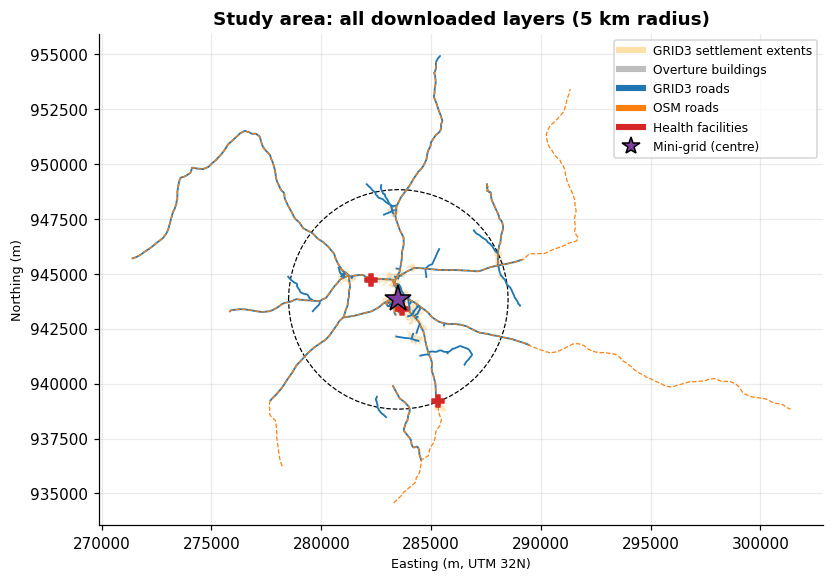

In [ ]:
def base_ax(figsize=(8.5, 8.5), title=""):
    fig, ax = plt.subplots(figsize=figsize)
    gpd.GeoSeries([AOI], crs=CRS_PROJ).boundary.plot(ax=ax, color="k", lw=.8, ls="--")
    ax.plot(*MG_XY, marker="*", ms=18, color=PALETTE["mg"], mec="k", ls="", zorder=10)
    ax.set_aspect("equal"); ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Easting (m, UTM 32N)"); ax.set_ylabel("Northing (m)")
    return fig, ax

fig, ax = base_ax(title="Study area: all downloaded layers (5 km radius)")
handles = []
if len(L["g3_extents"]):
    L["g3_extents"].plot(ax=ax, color=PALETTE["ext"], alpha=.7, edgecolor="none"); handles.append(("GRID3 settlement extents", PALETTE["ext"]))
for key, lab in (("overture_bld", "Overture buildings"), ("osm_buildings", "OSM buildings")):
    if len(L[key]):
        L[key].plot(ax=ax, color=PALETTE["bld"], lw=0); handles.append((lab, PALETTE["bld"])); break
if len(L["g3_roads"]):
    L["g3_roads"].plot(ax=ax, color=PALETTE["road_g3"], lw=1.2); handles.append(("GRID3 roads", PALETTE["road_g3"]))
if len(L["osm_roads"]):
    L["osm_roads"].plot(ax=ax, color=PALETTE["road_osm"], lw=.8, ls="--"); handles.append(("OSM roads", PALETTE["road_osm"]))
if len(L["g3_health"]):
    L["g3_health"].plot(ax=ax, color=PALETTE["dest"], marker="P", markersize=60, zorder=9); handles.append(("Health facilities", PALETTE["dest"]))
leg = [Line2D([0], [0], color=c, lw=4, label=l) for l, c in handles] + [Line2D([0], [0], marker="*", color=PALETTE["mg"], mec="k", ls="", ms=12, label="Mini-grid (centre)")]
ax.legend(handles=leg, loc="upper right", fontsize=8, frameon=True)
plt.show()

## 4 · Road network and road condition (proposal §4.2)

GRID3 roads are the base network. OSM roads are added **only where they extend beyond 30 m of a GRID3 road**, which avoids parallel duplicate edges. Connectivity is reported, and small gaps can optionally be bridged (flagged as an assumption). Road condition has a proxy score (from class/surface attributes) and a field-survey score that overrides it where available.

In [ ]:
def clean_lines(gdf, src):
    if gdf.empty:
        return empty()
    g = gdf[gdf.geom_type.isin(["LineString", "MultiLineString"])].copy()
    if g.empty:
        return empty()
    g["geometry"] = g.geometry.intersection(AOI)
    g = g[~g.geometry.is_empty].explode(index_parts=False)
    g = g[g.geom_type == "LineString"].copy()
    g["src"] = src
    return g.reset_index(drop=True)

KEY_COLS = ("surface", "class", "type", "highway", "fclass", "road", "smoothness")
def proxy_score(df):
    cols = [c for c in df.columns if c != "geometry" and any(k in c.lower() for k in KEY_COLS)]
    if not cols:
        return pd.Series(0.5, index=df.index), cols
    txt = df[cols].astype(str).agg(" ".join, axis=1).str.lower()
    s = pd.Series(0.5, index=df.index)
    s[txt.str.contains(r"paved|asphalt|tarred|trunk|primary|secondary|motorway", regex=True)] = 0.90
    s[txt.str.contains(r"tertiary|residential|unclassified|service|street", regex=True)] = 0.60
    s[txt.str.contains(r"track|path|unpaved|dirt|earth|laterite|gravel|ground|footway", regex=True)] = 0.35
    return s, cols

def prep(key, label):
    g = clean_lines(L[key], label)
    if g.empty:
        return None
    g["road_score"], used = proxy_score(g)
    print(f"{label}: {len(g)} segments; attributes used for the proxy score: {used or 'none (default 0.5)'}")
    for c in used:
        print(f"  value counts for '{c}':", g[c].astype(str).value_counts(dropna=False).head(6).to_dict())
    print(f"  proxy score spread: min {g['road_score'].min():.2f}, max {g['road_score'].max():.2f}, distinct values {g['road_score'].nunique()}")
    return g

g3, osm = prep("g3_roads", "GRID3"), prep("osm_roads", "OSM")
parts = [g3[["src", "road_score", "geometry"]]] if g3 is not None else []
if g3 is not None and osm is not None:
    g3_buf = unary_union(list(g3.buffer(30)))
    shared = osm.intersection(g3_buf).length.sum() / osm.length.sum()
    extra = osm.copy()
    extra["geometry"] = osm.geometry.difference(g3_buf)
    extra = extra[~extra.geometry.is_empty].explode(index_parts=False)
    extra = extra[(extra.geom_type == "LineString") & (extra.length > 20)]
    print(f"\n{shared:.0%} of OSM road length lies within 30 m of a GRID3 road.")
    print("  ->", "OSM adds almost nothing beyond GRID3 (likely the same source)." if shared >= .9 else "OSM maps different roads; the extra pieces are added to the network.")
    print(f"  OSM-only road length added: {extra.length.sum()/1000:.2f} km")
    if len(extra):
        parts.append(extra[["src", "road_score", "geometry"]])
elif osm is not None:
    parts.append(osm[["src", "road_score", "geometry"]])
if not parts:
    raise SystemExit("No road lines found. Check rubochi_data/.")
ROADS = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=CRS_PROJ)
display(ROADS.assign(len_m=ROADS.length).groupby("src").agg(segments=("len_m", "size"), length_km=("len_m", lambda s: round(s.sum() / 1000, 2))))

GRID3: 123 segments; attributes used for the proxy score: ['class', 'road_surface', 'subclass']
  value counts for 'class': {'residential': 67, 'secondary': 25, 'track': 13, 'unclassified': 7, 'Unknown': 6, 'tertiary': 5}
  value counts for 'road_surface': {'': 89, 'paved': 26, 'unpaved': 8}
  value counts for 'subclass': {'': 117, 'None': 6}
  proxy score spread: min 0.35, max 0.90, distinct values 4
OSM: 29 segments; attributes used for the proxy score: ['highway', 'surface']
  value counts for 'highway': {'secondary': 12, 'unclassified': 5, 'tertiary': 4, 'residential': 4, 'track': 4}
  value counts for 'surface': {'paved': 16, 'unpaved': 8, 'None': 5}
  proxy score spread: min 0.35, max 0.90, distinct values 3

100% of OSM road length lies within 30 m of a GRID3 road.
  -> OSM adds almost nothing beyond GRID3 (likely the same source).
  OSM-only road length added: 0.00 km


,segments,length_km
src,,
GRID3,123,64.6


Graph: 157 nodes, 165 edges
Components: 11 before bridging, 8 after (3 bridges of <= 100 m, ASSUMED links to verify)
Largest component: 138 nodes, 60.6 km (94% of road length)


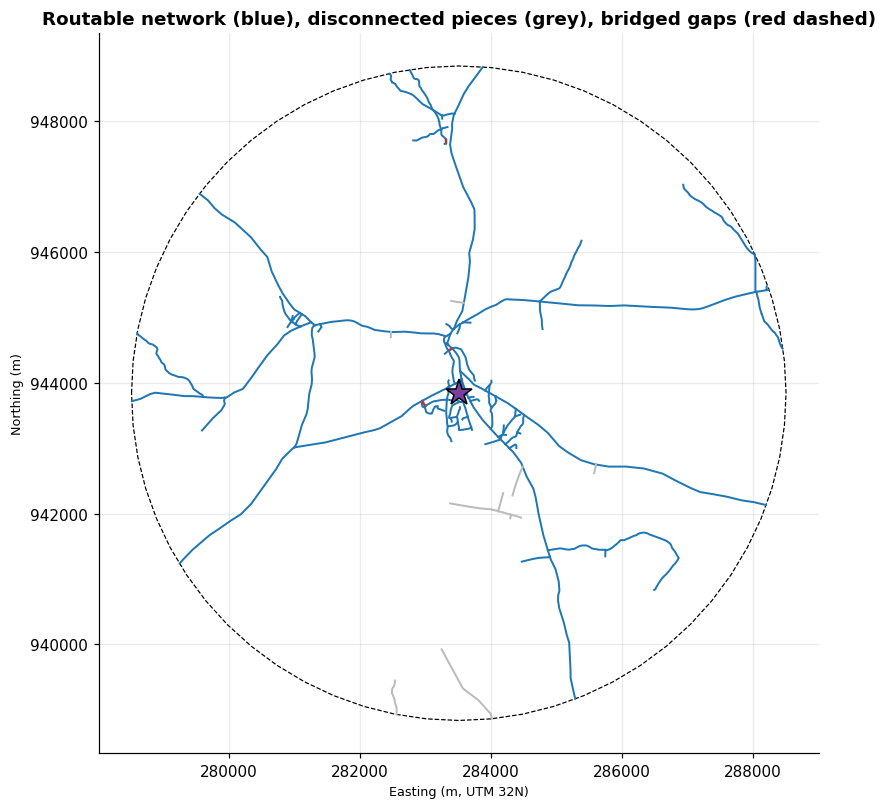

In [ ]:
def build_graph(lines, snap=SNAP_M):
    merged = unary_union(list(lines.geometry))
    segs = [merged] if merged.geom_type == "LineString" else list(merged.geoms)
    key = lambda c: (round(c[0] / snap) * snap, round(c[1] / snap) * snap)
    G = nx.Graph()
    for s in segs:
        if s.geom_type != "LineString" or len(s.coords) < 2:
            continue
        a, b = key(s.coords[0]), key(s.coords[-1])
        if a == b:
            continue
        if G.has_edge(a, b) and G[a][b]["length"] <= s.length:
            continue
        G.add_edge(a, b, length=s.length, geom=s, bridged=False)
    return G

def bridge_gaps(G, max_gap):
    """Join each disconnected piece to the main network if the closest nodes are within max_gap metres."""
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    main_nodes = list(comps[0]); main_xy = np.array(main_nodes, float)
    added = []
    for comp in comps[1:]:
        cn = list(comp); cxy = np.array(cn, float)
        d2 = ((cxy[:, None, :] - main_xy[None, :, :]) ** 2).sum(-1)
        i, j = np.unravel_index(d2.argmin(), d2.shape)
        d = math.sqrt(d2[i, j])
        if d <= max_gap:
            a, b = cn[i], main_nodes[j]
            G.add_edge(a, b, length=d, geom=LineString([a, b]), bridged=True)
            added.append((a, b, d))
            main_nodes += cn; main_xy = np.vstack([main_xy, cxy])
    return added

G = build_graph(ROADS)
assert G.number_of_nodes() > 0, "Graph is empty."
n_before = nx.number_connected_components(G)
bridges = bridge_gaps(G, BRIDGE_GAPS_M) if BRIDGE_GAPS_M > 0 else []
comps = sorted(nx.connected_components(G), key=len, reverse=True)
Gc = G.subgraph(comps[0]).copy()
tot_len  = sum(d["length"] for *_, d in G.edges(data=True))
main_len = sum(d["length"] for *_, d in Gc.edges(data=True))
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Components: {n_before} before bridging, {len(comps)} after ({len(bridges)} bridges of <= {BRIDGE_GAPS_M} m, ASSUMED links to verify)")
print(f"Largest component: {Gc.number_of_nodes()} nodes, {main_len/1000:.1f} km ({main_len/tot_len:.0%} of road length)")

nodes = list(Gc.nodes); node_xy = np.array(nodes, float); node_index = {n: i for i, n in enumerate(nodes)}

fig, ax = base_ax(title="Routable network (blue), disconnected pieces (grey), bridged gaps (red dashed)")
for a, b, d in G.edges(data=True):
    x, y = d["geom"].xy
    if d.get("bridged"):
        ax.plot(x, y, color="#d62728", lw=1.6, ls="--")
    else:
        ax.plot(x, y, color=PALETTE["road_g3"] if a in Gc else "#bbbbbb", lw=1.3)
plt.show()

In [ ]:
# optional: elevation at network nodes (SRTM 30 m via OpenTopoData) -> grades
GRADE = None
if FETCH_ELEVATION:
    ll = gpd.GeoSeries([Point(n) for n in nodes], crs=CRS_PROJ).to_crs(CRS_GEO)
    elev = {}
    for i in range(0, len(nodes), 100):
        loc = "|".join(f"{p.y:.6f},{p.x:.6f}" for p in ll.iloc[i:i + 100])
        try:
            r = requests.get("https://api.opentopodata.org/v1/srtm30m", params={"locations": loc}, headers=HDR, timeout=60).json()
            for n, res in zip(nodes[i:i + 100], r["results"]):
                elev[n] = res["elevation"]
        except Exception as ex:
            print("Elevation request failed:", ex); break
        time.sleep(1.2)
    rows = []
    for a, b, d in Gc.edges(data=True):
        if elev.get(a) is not None and elev.get(b) is not None and d["length"] > 20:
            rows.append((d["length"], abs(elev[a] - elev[b]) / d["length"]))
    if rows:
        GRADE = pd.DataFrame(rows, columns=["length_m", "grade"])
        steep = GRADE.loc[GRADE["grade"] > 0.06, "length_m"].sum() / GRADE["length_m"].sum()
        print(f"Elevation range {min(elev.values()):.0f}-{max(elev.values()):.0f} m; mean grade {GRADE['grade'].mean():.1%}; "
              f"{steep:.0%} of sampled road length steeper than 6 % (SRTM is coarse: treat as indicative).")
else:
    print("Elevation skipped (set FETCH_ELEVATION = True to sample SRTM along the network).")

Elevation skipped (set FETCH_ELEVATION = True to sample SRTM along the network).


### Field survey (rubric and template)
One row per surveyed road segment or point (KoboToolbox, ODK or QField work well). The rubric converts observations into a 0–1 condition score. Weights are provisional.

In [ ]:
SURV_RUBRIC = {"surface": {"paved": 1.0, "gravel": 0.6, "earth": 0.4},
               "damage": {"none": 1.0, "minor": 0.7, "severe": 0.3},
               "drainage": {"good": 1.0, "poor": 0.6, "flooded": 0.2}}
SURV_W = {"surface": 0.40, "damage": 0.35, "drainage": 0.25}

tmpl = pd.DataFrame([["EXAMPLE_DELETE_ME", 8.53, 7.03, "gravel", "minor", "poor", "yes", "photo_001.jpg"]],
                    columns=["segment_id", "lat", "lon", "surface", "damage", "drainage", "passable", "photo"])
SURVEY.parent.mkdir(exist_ok=True)
tmpl.to_csv(SURVEY.parent / "road_survey_TEMPLATE.csv", index=False)

SV = None
if SURVEY.exists():
    sv = pd.read_csv(SURVEY)
    for c in SURV_W:
        sv[c + "_s"] = sv[c].astype(str).str.lower().str.strip().map(SURV_RUBRIC[c])
    sv["road_score"] = sum(SURV_W[c] * sv[c + "_s"] for c in SURV_W)
    if "passable" in sv.columns:
        blocked = sv["passable"].astype(str).str.lower().str.strip().eq("no")
        sv.loc[blocked, "road_score"] = sv.loc[blocked, "road_score"].clip(upper=0.15)
    SV = gpd.GeoDataFrame(sv, geometry=gpd.points_from_xy(sv["lon"], sv["lat"]), crs=CRS_GEO).to_crs(CRS_PROJ).dropna(subset=["road_score"])
    print(f"Survey loaded: {len(SV)} scored points; mean score {SV['road_score'].mean():.2f}")
else:
    print("No survey file yet -> road condition uses the attribute proxy only (flagged in outputs).")

No survey file yet -> road condition uses the attribute proxy only (flagged in outputs).


## 5 · Destinations, buildings and population (proposal §4.3)

Destinations come from every available layer. Each gets a **weight** (an **ASSUMPTION**: refine with local verification). Overture and extra GRID3 layers are classified by keyword (school, market/shop, health, fuel, transport, worship). Settlement extents act as *demand clusters*, weighted by building count.

Separately, a **demand layer** (population points) supports the coverage analysis and demand-based fleet sizing. Priority: WorldPop raster → building footprints × persons per building (**ASSUMPTION**) → GRID3 extents.

In [ ]:
AMEN_W = {"marketplace": ("market", 3), "bus_station": ("transport hub", 3), "school": ("school", 2), "college": ("school", 2),
          "university": ("school", 2), "kindergarten": ("school", 1.5), "clinic": ("health", 2), "hospital": ("health", 2),
          "doctors": ("health", 2), "pharmacy": ("health", 1.5), "fuel": ("fuel station", 2), "bank": ("commercial", 1.5),
          "restaurant": ("commercial", 1), "place_of_worship": ("worship", 1), "townhall": ("public service", 1.5), "police": ("public service", 1.5)}
KW = [("school|education|college|universit|kindergarten|nursery", "school", 2.0),
      ("market|grocery|supermarket|shopping|retail|convenience|store|shop|trader", "market / shop", 2.0),
      ("hospital|clinic|pharmac|health|doctor|medical", "health", 2.0),
      ("gas_station|fuel|petrol", "fuel station", 2.0),
      ("bus_station|taxi|transport|motorcycle|tricycle|terminal", "transport hub", 3.0),
      ("mosque|church|religio|worship", "worship", 1.0),
      ("bank|atm|restaurant|food|bar|cafe|hotel|salon|barber", "commercial", 1.5)]
def classify(text):
    t = str(text).lower()
    for pat, typ, w in KW:
        if pd.Series([t]).str.contains(pat, regex=True).iloc[0]:
            return typ, w
    return "other POI", 1.0

def pick(v):
    if isinstance(v, dict):
        return v.get("primary")
    if isinstance(v, str):
        try:
            j = json.loads(v)
            return j.get("primary") if isinstance(j, dict) else v
        except Exception:
            return v
    return None

dest_parts = []
def add_rows(gdf, types, weights, names):
    if gdf.empty:
        return
    dest_parts.append(gpd.GeoDataFrame({"type": list(types), "weight": list(weights), "name": list(names)},
                      geometry=list(gdf.geometry.representative_point()), crs=CRS_PROJ))
def add(gdf, typ, weight=1.0, name_col=None, weights=None):
    if gdf.empty:
        return
    n = len(gdf)
    names = gdf[name_col].astype(str).tolist() if name_col else [typ] * n
    add_rows(gdf, [typ] * n, weights if weights is not None else [weight] * n, names)

add(L["g3_names"],  "settlement", 1.0, first_col(L["g3_names"], ["name", "settlement_name", "settlement", "ward_name"]) if len(L["g3_names"]) else None)
add(L["g3_health"], "health", 2.0, first_col(L["g3_health"], ["primary_name", "name", "facility_name"]) if len(L["g3_health"]) else None)
add(L["osm_places"], "place", 1.0, first_col(L["osm_places"], ["name"]) if len(L["osm_places"]) else None)

am = L["osm_amenity"]
if len(am) and "amenity" in am.columns:
    for val, sub in am.groupby("amenity"):
        typ, w = AMEN_W.get(val, ("other amenity", 1.0))
        add(sub, typ, w, first_col(sub, ["name"]))

ov = L["overture_poi"]
if len(ov):
    cat = ov["categories"].map(pick) if "categories" in ov.columns else pd.Series([None] * len(ov), index=ov.index)
    nme = ov["names"].map(pick) if "names" in ov.columns else pd.Series([None] * len(ov), index=ov.index)
    cls = [classify(c) for c in cat]
    add_rows(ov, [c[0] for c in cls], [c[1] for c in cls], nme.fillna("overture POI").astype(str))

for k in [k for k in L if k.startswith("x_")]:
    typ, w = classify(k[2:])
    add(L[k], typ, w, first_col(L[k], ["name", "school_name", "market_name", "primary_name"]) if len(L[k]) else None)

ext = L["g3_extents"]
bc_col = first_col(ext, ["building_count"]) if len(ext) else None
if len(ext):
    if bc_col:
        bc = pd.to_numeric(ext[bc_col], errors="coerce").fillna(0)
        add(ext, "demand cluster", weights=(1 + 2 * bc / max(bc.max(), 1)).tolist())
    else:
        add(ext, "demand cluster", 1.5)
if not dest_parts:
    raise SystemExit("No destination layers available.")
DEST = gpd.GeoDataFrame(pd.concat(dest_parts, ignore_index=True), geometry="geometry", crs=CRS_PROJ)

def snap(x, y):
    d = np.hypot(node_xy[:, 0] - x, node_xy[:, 1] - y)
    i = int(d.argmin())
    return nodes[i], float(d[i])

tmp = [snap(p.x, p.y) for p in DEST.geometry]
DEST["node"], DEST["snap_m"] = [t[0] for t in tmp], [t[1] for t in tmp]
DEST["on_network"] = DEST["snap_m"] <= MAX_SNAP_DEST_M
display(DEST.groupby("type").agg(count=("type", "size"), on_network=("on_network", "sum"), mean_weight=("weight", "mean")).round(2).sort_values("count", ascending=False))
print(f"{(~DEST['on_network']).sum()} of {len(DEST)} destinations are > {MAX_SNAP_DEST_M} m from the routable network.")

,count,on_network,mean_weight
type,,,
demand cluster,67,57,1.44
settlement,25,22,1.00
health,3,2,2.00
other POI,2,0,1.00


16 of 97 destinations are > 500 m from the routable network.


In [ ]:
def snap_many(xy, chunk=2000):
    """Nearest network node (index into `nodes`) and distance for an (n, 2) array of coordinates."""
    idx = np.empty(len(xy), int); dist = np.empty(len(xy))
    for i in range(0, len(xy), chunk):
        c = xy[i:i + chunk]
        d2 = (c[:, None, 0] - node_xy[None, :, 0]) ** 2 + (c[:, None, 1] - node_xy[None, :, 1]) ** 2
        j = d2.argmin(axis=1)
        idx[i:i + chunk] = j
        dist[i:i + chunk] = np.sqrt(d2[np.arange(len(c)), j])
    return idx, dist

def read_worldpop():
    if not POP_TIF.exists():
        return None
    try:
        import rasterio
        from rasterio.windows import from_bounds
        from rasterio.transform import xy as rio_xy
    except ImportError:
        print("rasterio not installed (pip install rasterio) -> WorldPop raster skipped."); return None
    minx, miny, maxx, maxy = gpd.GeoSeries([AOI], crs=CRS_PROJ).to_crs(CRS_GEO).total_bounds
    with rasterio.open(POP_TIF) as src:
        win = from_bounds(minx, miny, maxx, maxy, src.transform)
        arr = src.read(1, window=win).astype(float)
        tr = src.window_transform(win)
        nod = src.nodata
    if nod is not None:
        arr[arr == nod] = 0
    arr[~np.isfinite(arr)] = 0; arr[arr < 0] = 0
    r, c = np.nonzero(arr > 0)
    if len(r) == 0:
        return None
    xs, ys = rio_xy(tr, r, c)
    pts = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=CRS_GEO).to_crs(CRS_PROJ)
    df = pd.DataFrame({"x": pts.x.values, "y": pts.y.values, "pop": arr[r, c]})
    return df[np.hypot(df["x"] - MG_XY[0], df["y"] - MG_XY[1]) <= RADIUS_M].reset_index(drop=True)

DEMAND, POP_SOURCE = read_worldpop(), None
if DEMAND is not None:
    POP_SOURCE = "WorldPop raster"
elif BUILD_SRC:
    bp = L["osm_buildings" if BUILD_SRC == "OSM" else "overture_bld"]
    bp = bp.geometry.representative_point()
    bp = bp[bp.within(AOI)]
    DEMAND = pd.DataFrame({"x": bp.x.values, "y": bp.y.values, "pop": PERSONS_PER_BUILDING})
    POP_SOURCE = f"{BUILD_SRC} buildings x {PERSONS_PER_BUILDING:g} persons/building (ASSUMPTION)"
elif len(ext) and bc_col:
    cp = ext.geometry.representative_point()
    DEMAND = pd.DataFrame({"x": cp.x.values, "y": cp.y.values,
                           "pop": pd.to_numeric(ext[bc_col], errors="coerce").fillna(0).values * PERSONS_PER_BUILDING})
    POP_SOURCE = f"GRID3 extent centroids x building_count x {PERSONS_PER_BUILDING:g} (ASSUMPTION, coarse)"
else:
    raise SystemExit("No population or building source available.")

idx, dist = snap_many(DEMAND[["x", "y"]].values)
DEMAND["node_idx"], DEMAND["snap_m"] = idx, dist
DEMAND["on_net"] = DEMAND["snap_m"] <= MAX_SNAP_DEST_M
print(f"Population source: {POP_SOURCE}")
print(f"Demand points: {len(DEMAND):,}; total population in box: {DEMAND['pop'].sum():,.0f}; "
      f"{DEMAND.loc[DEMAND['on_net'], 'pop'].sum() / DEMAND['pop'].sum():.0%} within {MAX_SNAP_DEST_M} m of the routable network")

Population source: Overture buildings x 4 persons/building (ASSUMPTION)
Demand points: 2,671; total population in box: 10,684; 93% within 500 m of the routable network


## 6 · Charging-location screening (proposal §4.3)

Candidates are network nodes thinned to one per grid cell, plus nodes nearest to important destinations and the mini-grid. Each is scored on three criteria normalised to 0–1:

- **R, road accessibility and condition:** length-weighted mean road score within `ROAD_BUFFER_M` (survey score where available, attribute proxy otherwise).
- **D, proximity to destinations:** sum of `weight × (1 − d/catchment)` using *network* distance.
- **C, charging-site accessibility:** closeness (network distance) to the mini-grid. **Provisional definition**: replace it when site layout data is available.

`SI = 0.35·R + 0.35·D + 0.30·C`: weights are provisional and tested in section 9.

In [ ]:
mg_node, mg_snap = snap(*MG_XY)
print(f"Mini-grid centre snaps to the road network at {mg_snap:.0f} m")

cell = {}
for n in nodes:
    k = (int(n[0] // CAND_CELL_M), int(n[1] // CAND_CELL_M))
    if k not in cell or Gc.degree(n) > Gc.degree(cell[k]):
        cell[k] = n
cand_nodes = set(cell.values())
cand_nodes |= set(DEST.loc[DEST["on_network"] & (DEST["weight"] >= 2), "node"])
cand_nodes.add(mg_node)
cand_nodes = list(cand_nodes)

CAND = gpd.GeoDataFrame({"node": cand_nodes}, geometry=[Point(n) for n in cand_nodes], crs=CRS_PROJ)
CAND["is_minigrid"] = [n == mg_node for n in cand_nodes]
print(f"{len(CAND)} candidate locations")

DIST = {n: nx.single_source_dijkstra_path_length(Gc, n, weight="length") for n in CAND["node"]}
dest_on = DEST[DEST["on_network"]]

def minmax(a):
    a = np.asarray(a, float)
    lo, hi = np.nanmin(a), np.nanmax(a)
    return np.full_like(a, .5) if hi - lo < 1e-12 else (a - lo) / (hi - lo)

def compute_D(catch):
    out = []
    for n in CAND["node"]:
        dm, tot = DIST[n], 0.0
        for dn, w, sm in zip(dest_on["node"], dest_on["weight"], dest_on["snap_m"]):
            d = dm.get(dn, np.inf) + sm
            if d < catch:
                tot += w * (1 - d / catch)
        out.append(tot)
    return np.array(out)

sidx = ROADS.sindex
def local_road_score(pt):
    buf = pt.buffer(ROAD_BUFFER_M)
    idx = sidx.query(buf, predicate="intersects")
    if len(idx) == 0:
        return np.nan
    seg = ROADS.iloc[idx]
    ln = seg.geometry.intersection(buf).length.values
    return float(np.average(seg["road_score"].values, weights=ln)) if ln.sum() > 0 else np.nan

R_raw, R_src = [], []
for pt in CAND.geometry:
    val, src = local_road_score(pt), "proxy"
    if SV is not None and len(SV):
        near = SV[SV.geometry.distance(pt) <= 400]
        if len(near):
            val, src = float(near["road_score"].mean()), "survey"
    R_raw.append(val); R_src.append(src)
R_raw = np.array(R_raw, float)
R_raw = np.where(np.isnan(R_raw), np.nanmin(R_raw), R_raw)

dist_mg = np.array([DIST[n].get(mg_node, np.inf) for n in CAND["node"]])
dist_mg = np.where(np.isinf(dist_mg), np.nanmax(dist_mg[np.isfinite(dist_mg)]), dist_mg)

CAND["R"], CAND["D"], CAND["C"] = minmax(R_raw), minmax(compute_D(CATCHMENT_M)), 1 - minmax(dist_mg)
CAND["R_source"] = R_src
CAND["dist_to_minigrid_m"] = dist_mg.round(0)
CAND["SI"] = WEIGHTS["R"] * CAND["R"] + WEIGHTS["D"] * CAND["D"] + WEIGHTS["C"] * CAND["C"]
CAND = CAND.sort_values("SI", ascending=False).reset_index(drop=True)
CAND["id"] = [f"C{i + 1:02d}" for i in range(len(CAND))]
ll = CAND.to_crs(CRS_GEO)
CAND["lat"], CAND["lon"] = ll.geometry.y.values, ll.geometry.x.values

top = CAND.head(10)[["id", "SI", "R", "D", "C", "R_source", "dist_to_minigrid_m", "lat", "lon", "is_minigrid"]]
top.round({"SI": 3, "R": 3, "D": 3, "C": 3, "lat": 6, "lon": 6})

Mini-grid centre snaps to the road network at 60 m
71 candidate locations


,id,SI,R,D,C,R_source,dist_to_minigrid_m,lat,lon,is_minigrid
0,C01,0.824,0.536,1.000,0.956,proxy,352.0,8.536670,7.033362,False
1,C02,0.804,0.654,0.865,0.908,proxy,736.0,8.539738,7.032256,False
2,C03,0.797,0.451,0.992,0.974,proxy,206.0,8.535315,7.033550,False
3,C04,0.777,0.654,0.795,0.900,proxy,803.0,8.539464,7.031713,False
4,C05,0.774,0.623,0.825,0.892,proxy,862.0,8.540457,7.031344,False
5,C06,0.753,0.398,0.930,0.961,proxy,314.0,8.534859,7.032644,False
6,C07,0.719,0.502,0.749,0.936,proxy,514.0,8.535306,7.031825,False
7,C08,0.712,0.585,0.708,0.863,proxy,1094.0,8.542542,7.032514,False
8,C09,0.703,0.307,0.844,1.000,proxy,0.0,8.533508,7.033741,True
9,C10,0.660,0.330,0.739,0.953,proxy,375.0,8.532683,7.031566,False


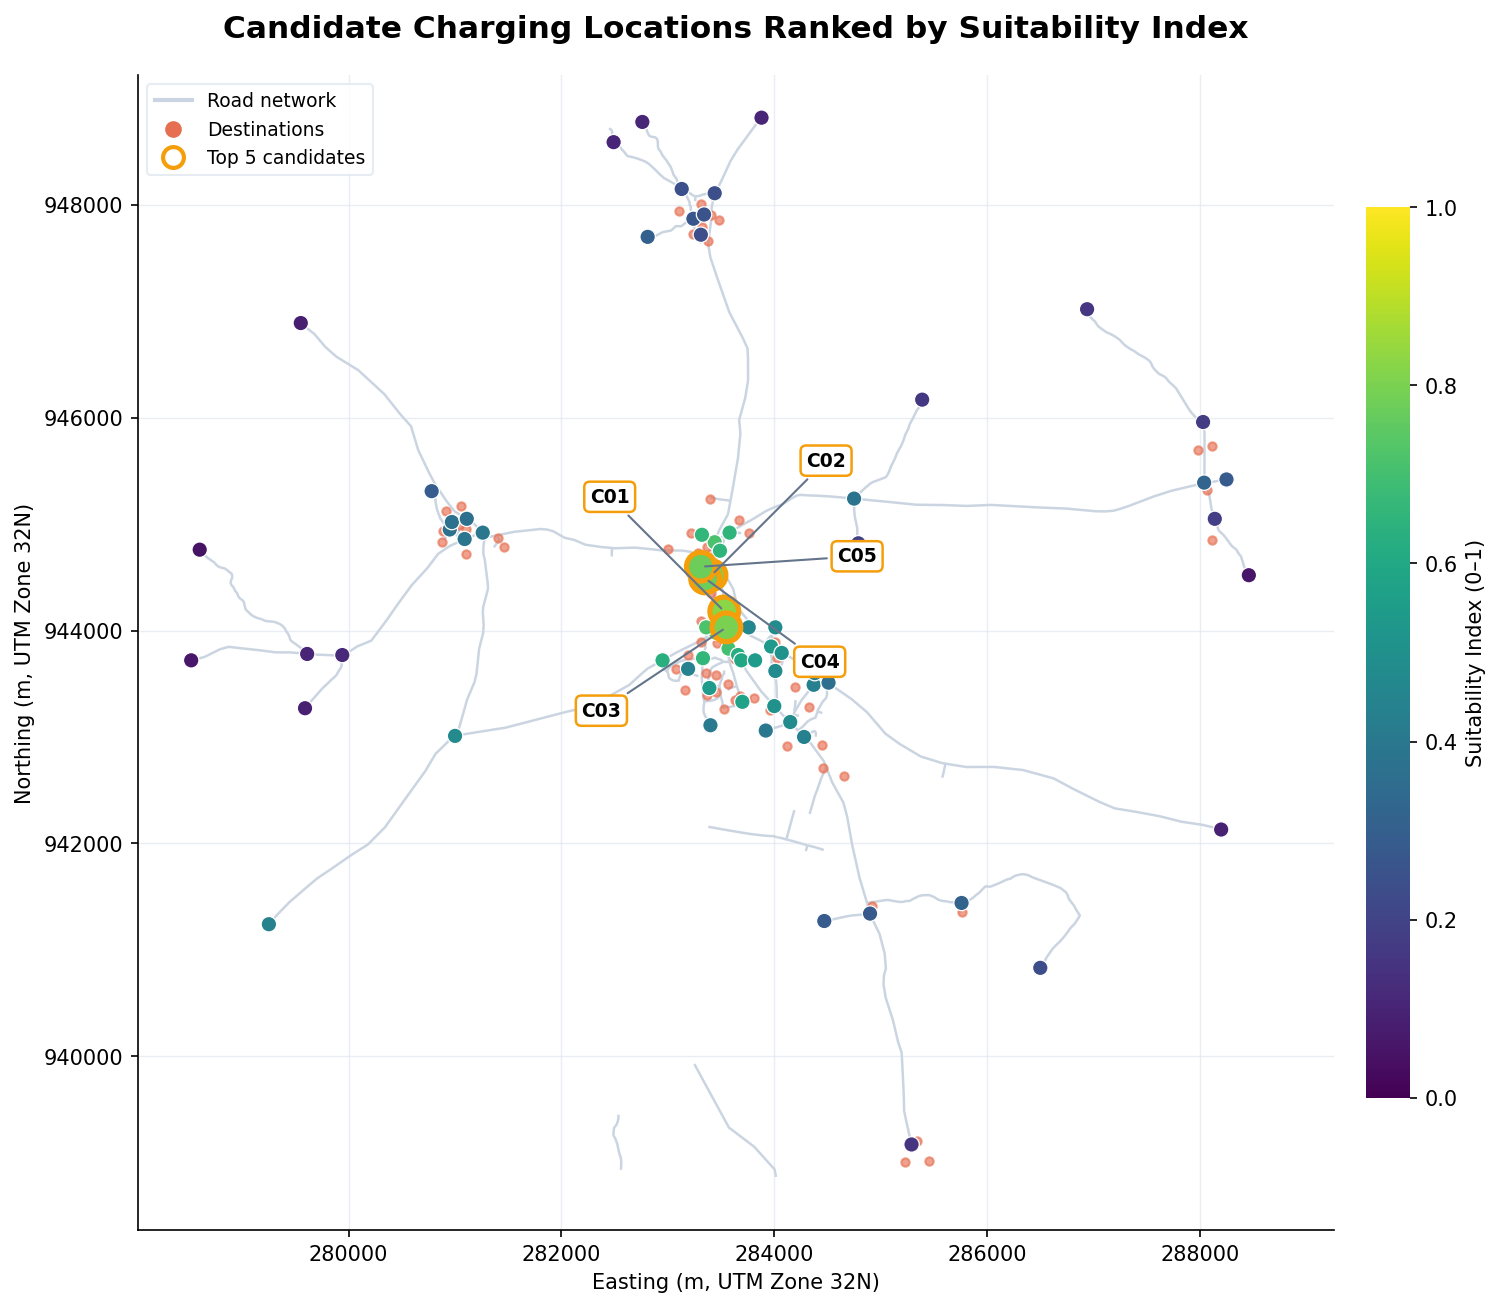

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize

# ==================================================
# PREPARE DATA
# ==================================================
candidates = CAND.sort_values("SI", ascending=False).copy()
top5 = candidates.head(5)
others = candidates.iloc[5:]

# Ensure consistent CRS
roads_plot = ROADS.to_crs(candidates.crs)
dest_plot = dest_on.to_crs(candidates.crs)

# ==================================================
# GRAPH 1: SPATIAL SUITABILITY MAP
# ==================================================
fig, ax = plt.subplots(figsize=(10, 9), dpi=150)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Roads
roads_plot.plot(
    ax=ax,
    color="#CBD5E1",
    linewidth=1.2,
    zorder=1
)

# Destinations
dest_plot.plot(
    ax=ax,
    color="#E76F51",
    markersize=16,
    alpha=0.65,
    zorder=3
)

# Candidate locations
norm = Normalize(vmin=0, vmax=1)

sc = ax.scatter(
    others.geometry.x,
    others.geometry.y,
    c=others["SI"],
    cmap="viridis",
    norm=norm,
    s=55,
    edgecolors="white",
    linewidths=0.6,
    zorder=5
)

# Top five candidate markers
ax.scatter(
    top5.geometry.x,
    top5.geometry.y,
    c=top5["SI"],
    cmap="viridis",
    norm=norm,
    s=190,
    edgecolors="#F59E0B",
    linewidths=2.5,
    zorder=8
)

# Label offsets (points, not metres)
offsets = [
    (-55, 55),
    (55, 55),
    (-60, -40),
    (55, -40),
    (75, 5)
]

for (_, r), (dx, dy) in zip(top5.iterrows(), offsets):
    ax.annotate(
        str(r["id"]),
        xy=(r.geometry.x, r.geometry.y),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="#F59E0B",
            linewidth=1.2
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="#64748B",
            linewidth=1
        ),
        zorder=12
    )

# Mini-grid centre, if defined
if "MG_POINT" in globals():
    ax.scatter(
        MG_POINT.x,
        MG_POINT.y,
        marker="*",
        s=350,
        color="#8B5CF6",
        edgecolors="black",
        linewidths=1,
        zorder=10
    )

# Title and axes
ax.set_title(
    "Candidate Charging Locations Ranked by Suitability Index",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Easting (m, UTM Zone 32N)", fontsize=10)
ax.set_ylabel("Northing (m, UTM Zone 32N)", fontsize=10)
ax.set_aspect("equal")

ax.grid(
    color="#E2E8F0",
    linewidth=0.7,
    alpha=0.7
)
ax.set_axisbelow(True)

# Add map margins for annotations
xmin, ymin, xmax, ymax = roads_plot.total_bounds
ax.set_xlim(xmin - 500, xmax + 800)
ax.set_ylim(ymin - 500, ymax + 400)

# Legend
legend_handles = [
    Line2D([0], [0], color="#CBD5E1", lw=2,
           label="Road network"),
    Line2D([0], [0], marker="o", linestyle="",
           color="#E76F51", markersize=7,
           label="Destinations"),
    Line2D([0], [0], marker="o", linestyle="",
           markerfacecolor="none",
           markeredgecolor="#F59E0B",
           markeredgewidth=2,
           markersize=10,
           label="Top 5 candidates")
]

if "MG_POINT" in globals():
    legend_handles.append(
        Line2D([0], [0], marker="*", linestyle="",
               markerfacecolor="#8B5CF6",
               markeredgecolor="black",
               markersize=12,
               label="Mini-grid centre")
    )

ax.legend(
    handles=legend_handles,
    loc="upper left",
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor="#E2E8F0"
)

# Colorbar
cbar = fig.colorbar(
    sc,
    ax=ax,
    fraction=0.035,
    pad=0.025,
    shrink=0.80
)

cbar.set_label("Suitability Index (0–1)", fontsize=10)
cbar.outline.set_visible(False)

plt.tight_layout()

plt.savefig(
    "rubochi_candidate_suitability_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


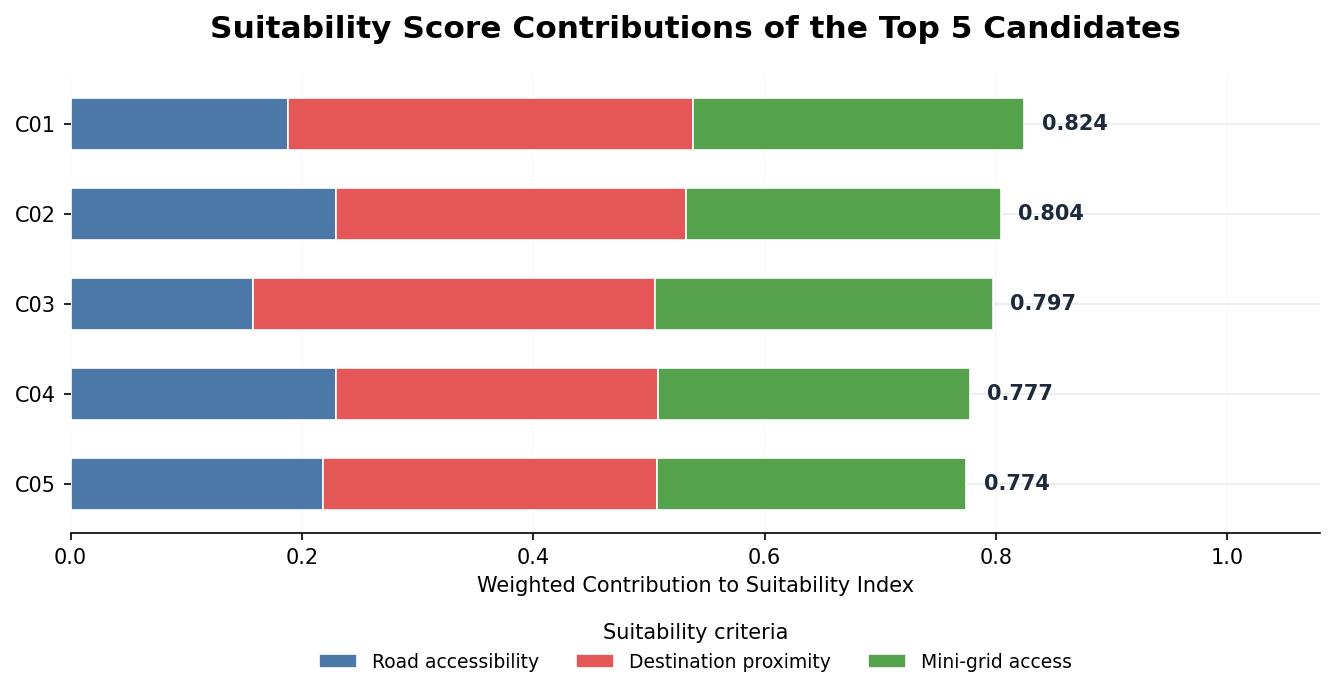

In [ ]:

# ==================================================
# GRAPH 2: TOP FIVE SUITABILITY CONTRIBUTIONS
# ==================================================

top5 = CAND.nlargest(5, "SI").copy()

contrib = pd.DataFrame(
    {
        "Road accessibility": WEIGHTS["R"] * top5["R"].values,
        "Destination proximity": WEIGHTS["D"] * top5["D"].values,
        "Mini-grid access": WEIGHTS["C"] * top5["C"].values
    },
    index=top5["id"].astype(str).values
)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

colors = ["#4C78A8", "#E45756", "#54A24B"]

contrib.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=colors,
    width=0.58,
    edgecolor="white",
    linewidth=0.8
)

# Highest candidate at top
ax.invert_yaxis()

# Label scores
for i, (_, row) in enumerate(contrib.iterrows()):
    total = row.sum()

    ax.text(
        total + 0.015,
        i,
        f"{total:.3f}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#1E293B"
    )

ax.set_xlim(0, 1.08)

ax.set_title(
    "Suitability Score Contributions of the Top 5 Candidates",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Weighted Contribution to Suitability Index",
    fontsize=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    color="#E2E8F0",
    linewidth=0.8
)
ax.set_axisbelow(True)

# Remove unnecessary borders
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.legend(
    title="Suitability criteria",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.34),
    ncol=3,
    frameon=False,
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "rubochi_top5_score_contributions.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


### Zones and ranking variants
The run showed that single-point ranks are fragile but the *area* is stable. Top candidates within `ZONE_LINK_M` of each other are merged into **zones**, which is the better thing to report. The variants show how much the answer depends on the mini-grid-proximity criterion `C`.

In [ ]:
def zones_from(cand, n=15, link=ZONE_LINK_M):
    t = cand.head(n).copy()
    xy = np.c_[t.geometry.x, t.geometry.y]
    parent = list(range(len(t)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    for i in range(len(t)):
        for j in range(i + 1, len(t)):
            if np.hypot(*(xy[i] - xy[j])) <= link:
                parent[find(i)] = find(j)
    t["root"] = [find(i) for i in range(len(t))]
    order = t.groupby("root")["SI"].max().sort_values(ascending=False).index
    names = {r: f"Z{k + 1}" for k, r in enumerate(order)}
    t["zone"] = t["root"].map(names)
    return t

ZT = zones_from(CAND)
ZONES = (ZT.groupby("zone").agg(candidates=("id", "size"), best_id=("id", "first"), best_SI=("SI", "max"),
                                 lat=("lat", "mean"), lon=("lon", "mean"), mean_dist_to_minigrid_m=("dist_to_minigrid_m", "mean"))
           .sort_values("best_SI", ascending=False))
display(ZONES.round({"best_SI": 3, "lat": 5, "lon": 5, "mean_dist_to_minigrid_m": 0}))

VARIANTS = {"baseline (0.35/0.35/0.30)": WEIGHTS, "no mini-grid term (R+D only)": {"R": .5, "D": .5, "C": 0.0},
            "destinations only": {"R": 0.0, "D": 1.0, "C": 0.0}, "roads only": {"R": 1.0, "D": 0.0, "C": 0.0}}
base_top5 = set(CAND["id"].head(5))
rows = []
for name, w in VARIANTS.items():
    si = w["R"] * CAND["R"] + w["D"] * CAND["D"] + w["C"] * CAND["C"]
    t5 = CAND["id"][np.argsort(-si.values)[:5]].tolist()
    rows.append({"variant": name, "top5": ", ".join(t5), "overlap_with_baseline": len(set(t5) & base_top5),
                 "mean_dist_to_minigrid_m": round(CAND.loc[CAND["id"].isin(t5), "dist_to_minigrid_m"].mean())})
display(pd.DataFrame(rows))

,candidates,best_id,best_SI,lat,lon,mean_dist_to_minigrid_m
zone,,,,,,
Z1,15,C01,0.824,8.53762,7.03236,697.0


,variant,top5,overlap_with_baseline,mean_dist_to_minigrid_m
0,baseline (0.35/0.35/0.30),"C01, C02, C03, C04, C05",5,592
1,no mini-grid term (R+D only),"C01, C02, C04, C05, C03",5,592
2,destinations only,"C01, C03, C06, C02, C09",3,322
3,roads only,"C28, C26, C02, C04, C05",3,2181


## 7 · Coverage analysis: how many stations, serving whom?

For each candidate, which demand points lie within `COVER_CATCH_M` *along the network*? A greedy algorithm then picks stations one at a time, each adding the most **uncovered population**. This answers a different question from the suitability index and is less sensitive to the weights. Feeder distance from the mini-grid is reported for each chosen station, because sites far from the mini-grid cost more to connect.

In [ ]:
cand_arr = np.full((len(CAND), len(nodes)), np.inf)
for r, n in enumerate(CAND["node"]):
    for m, d in DIST[n].items():
        cand_arr[r, node_index[m]] = d

dem = DEMAND[DEMAND["on_net"]].reset_index(drop=True)
ni, sn, pp = dem["node_idx"].values, dem["snap_m"].values, dem["pop"].values
COV = (cand_arr[:, ni] + sn[None, :]) <= COVER_CATCH_M          # candidates x demand points
POP_ALL, POP_NET = DEMAND["pop"].sum(), pp.sum()

chosen, marg, covered = [], [], np.zeros(len(dem), bool)
for _ in range(N_STATIONS):
    gain = (COV & ~covered).astype(float) @ pp
    j = int(gain.argmax())
    if gain[j] <= 0:
        break
    chosen.append(j); marg.append(float(gain[j])); covered |= COV[j]
cum = np.cumsum(marg)

mg_i = int(CAND.index[CAND["is_minigrid"]][0])
mg_pop = float(pp[COV[mg_i]].sum())

ST = pd.DataFrame({"station": [f"S{k + 1}" for k in range(len(chosen))], "candidate": [CAND.loc[j, "id"] for j in chosen],
                   "SI": [CAND.loc[j, "SI"] for j in chosen], "added_population": marg,
                   "cumulative_population": cum, "cumulative_share_of_box": cum / POP_ALL,
                   "feeder_distance_m": [CAND.loc[j, "dist_to_minigrid_m"] for j in chosen],
                   "lat": [CAND.loc[j, "lat"] for j in chosen], "lon": [CAND.loc[j, "lon"] for j in chosen]})
display(ST.round({"SI": 3, "added_population": 0, "cumulative_population": 0, "cumulative_share_of_box": 3, "lat": 6, "lon": 6}))
print(f"Mini-grid site alone serves {mg_pop:,.0f} people ({mg_pop / POP_ALL:.0%} of the box population). "
      f"Population source: {POP_SOURCE}.")

,station,candidate,SI,added_population,cumulative_population,cumulative_share_of_box,feeder_distance_m,lat,lon
0,S1,C03,0.797,6700.0,6700.0,0.627,206.0,8.535315,7.033550
1,S2,C35,0.395,1364.0,8064.0,0.755,3090.0,8.543255,7.012712
2,S3,C44,0.303,1200.0,9264.0,0.867,5628.0,8.568457,7.026659
3,S4,C42,0.320,392.0,9656.0,0.904,5866.0,8.547814,7.074264
4,S5,C22,0.504,212.0,9868.0,0.924,1082.0,8.528646,7.037671


Mini-grid site alone serves 6,024 people (56% of the box population). Population source: Overture buildings x 4 persons/building (ASSUMPTION).


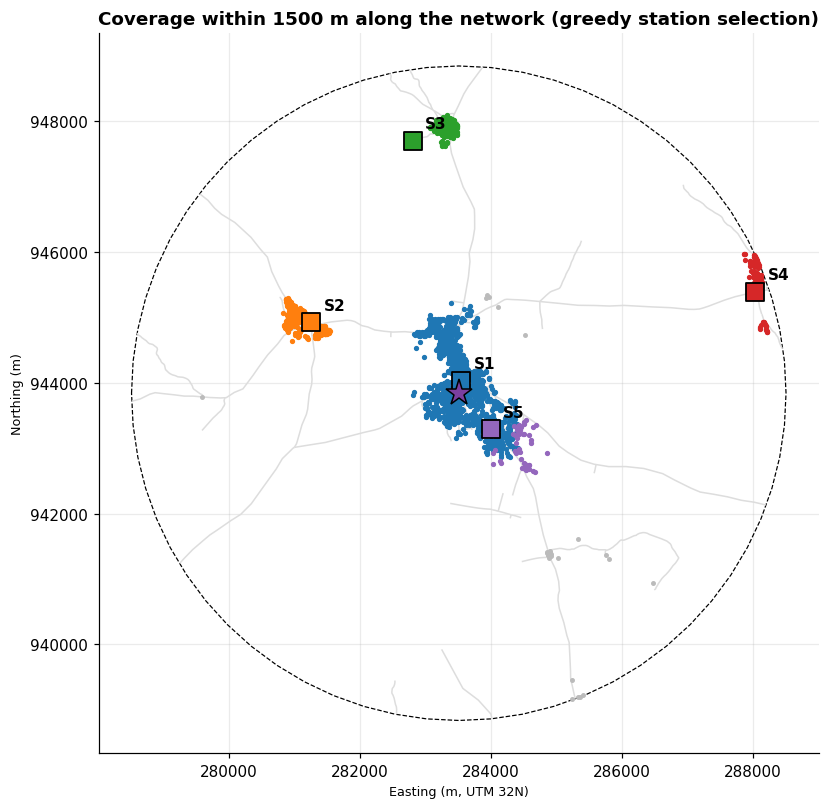

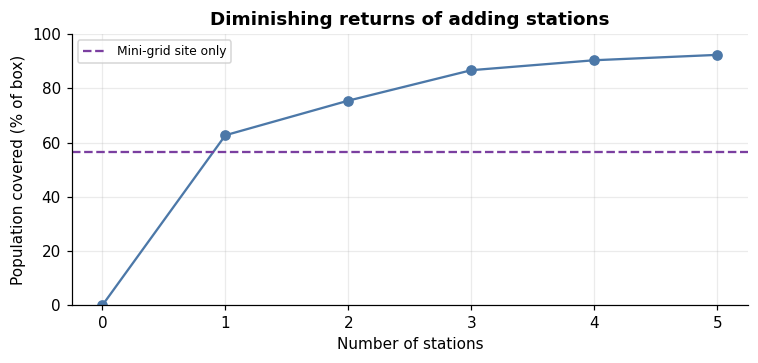

In [ ]:
assigned = np.full(len(dem), -1)
for k, j in enumerate(chosen):
    m = COV[j] & (assigned < 0)
    assigned[m] = k
fig, ax = base_ax(title=f"Coverage within {COVER_CATCH_M} m along the network (greedy station selection)")
ROADS.plot(ax=ax, color="#dddddd", lw=1)
cols = plt.cm.tab10(np.arange(10))
unc = assigned < 0
ax.scatter(dem["x"][unc], dem["y"][unc], s=5, color="#bbbbbb", label="Not covered", zorder=3)
for k in range(len(chosen)):
    m = assigned == k
    ax.scatter(dem["x"][m], dem["y"][m], s=6, color=cols[k], zorder=4)
for k, j in enumerate(chosen):
    g = CAND.loc[j, "geometry"]
    ax.scatter(g.x, g.y, marker="s", s=140, color=cols[k], edgecolor="k", lw=1.2, zorder=9)
    ax.annotate(f"S{k + 1}", (g.x, g.y), xytext=(8, 8), textcoords="offset points", fontweight="bold", zorder=11)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(0, len(chosen) + 1), np.r_[0, cum] / POP_ALL * 100, marker="o", color="#4c78a8")
ax.axhline(mg_pop / POP_ALL * 100, color="#7b3fa0", ls="--", label="Mini-grid site only")
ax.set_xlabel("Number of stations"); ax.set_ylabel("Population covered (% of box)"); ax.set_ylim(0, 100)
ax.set_title("Diminishing returns of adding stations", fontweight="bold"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

> **Reading the result.** If one or two stations already cover most of the *on-network* population, a small pilot is justified. A long tail of small, scattered clusters means more stations for little gain. Compare the first station with the mini-grid site: the gap is the **trade-off between demand coverage and feeder distance**.

## 8 · Fleet-energy calculator (proposal §4.4)

$$E_{\text{traction}} = \frac{N\,d\,e}{100}\qquad E_{\text{charging}} = \frac{E_{\text{traction}}}{\eta}$$

Two ways to set the fleet:
1. **Fixed-fleet scenarios** (as in v1): `N` is assumed directly.
2. **Demand-based scenarios** (new): `N` follows from the population served, motorcycle-taxi trips per resident, and trips per motorcycle. Total energy then scales with *passenger-km demand*:
$$E_{\text{charging}} = \frac{P \; t \; \ell \; \delta \; e}{100\,\eta}$$
with `P` population served, `t` trips per resident per day, `ℓ` mean trip length (km), `δ` empty-running multiplier.

> **ASSUMPTION.** All scenario values below are placeholders. Replace `t`, `ℓ`, `δ` and trips per motorcycle with a short rider and household survey, and `e`, `η`, charger rating with datasheet values.

In [ ]:
SC = pd.DataFrame({"N": [10, 30, 60], "d_km": [30, 45, 60], "e_kWh_100km": [4.0, 5.0, 6.0], "eta": [0.90, 0.85, 0.80],
                   "charger_kW": [1.5, 1.5, 1.5], "simult": [0.5, 0.6, 0.8]}, index=pd.Index(["Low", "Medium", "High"], name="scenario"))
def e_traction(N, d, e):      return N * d * e / 100
def e_charging(N, d, e, eta): return e_traction(N, d, e) / eta
SC["E_traction_kWh_day"] = e_traction(SC["N"], SC["d_km"], SC["e_kWh_100km"])
SC["E_charging_kWh_day"] = e_charging(SC["N"], SC["d_km"], SC["e_kWh_100km"], SC["eta"])
SC["Peak_charging_kW"]   = SC["N"] * SC["charger_kW"] * SC["simult"]
SC.round(1)

,N,d_km,e_kWh_100km,eta,charger_kW,simult,E_traction_kWh_day,E_charging_kWh_day,Peak_charging_kW
scenario,,,,,,,,,
Low,10,30,4.0,0.9,1.5,0.5,12.0,13.3,7.5
Medium,30,45,5.0,0.8,1.5,0.6,67.5,79.4,27.0
High,60,60,6.0,0.8,1.5,0.8,216.0,270.0,72.0


In [ ]:
# ---- demand-based scenarios ----
DM = pd.DataFrame({"trips_pp": [0.10, 0.25, 0.50],          # motorcycle-taxi trips per resident per day   (ASSUMPTION)
                   "trip_km": [2.0, 2.5, 3.0],              # mean trip length, km                         (ASSUMPTION)
                   "deadhead": [1.15, 1.25, 1.35],          # empty-running multiplier                     (ASSUMPTION)
                   "trips_per_bike": [25, 20, 15],          # trips one motorcycle completes per day       (ASSUMPTION)
                   "e_kWh_100km": [4.0, 5.0, 6.0], "eta": [0.90, 0.85, 0.80],
                   "charger_kW": [1.5, 1.5, 1.5], "simult": [0.5, 0.6, 0.8]}, index=SC.index)

def demand_energy(P, trips_pp, trip_km, deadhead, trips_per_bike, e_kWh_100km, eta, charger_kW=1.5, simult=0.6):
    trips = P * trips_pp
    N = math.ceil(trips / trips_per_bike) if trips > 0 else 0
    km = trips * trip_km * deadhead
    e_trac = km * e_kWh_100km / 100
    return {"trips_day": trips, "N_bikes": N, "km_day": km, "E_traction": e_trac, "E_charging": e_trac / eta, "peak_kW": N * charger_kW * simult}

SERVICE = {"Mini-grid site only": mg_pop}
for k in (1, 3, len(chosen)):
    if 0 < k <= len(chosen):
        SERVICE[f"Best {k} station{'s' if k > 1 else ''}"] = float(cum[k - 1])
DEFAULT_AREA = list(SERVICE)[-1] if len(SERVICE) > 1 else list(SERVICE)[0]

rows = []
for area, P in SERVICE.items():
    for sname, r in DM.iterrows():
        res = demand_energy(P, **r.to_dict())
        rows.append({"service_area": area, "scenario": sname, "population": round(P), **{k: round(v, 1) for k, v in res.items()}})
DEMSC = pd.DataFrame(rows)
display(DEMSC[DEMSC["service_area"] == DEFAULT_AREA].set_index("scenario"))
print(f"Default service area for later sections: '{DEFAULT_AREA}' ({SERVICE[DEFAULT_AREA]:,.0f} people). Population source: {POP_SOURCE}.")

,service_area,population,trips_day,N_bikes,km_day,E_traction,E_charging,peak_kW
scenario,,,,,,,,
Low,Best 5 stations,9868,986.8,40,2269.6,90.8,100.9,30.0
Medium,Best 5 stations,9868,2467.0,124,7709.4,385.5,453.5,111.6
High,Best 5 stations,9868,4934.0,329,19982.7,1199.0,1498.7,394.8


Default service area for later sections: 'Best 5 stations' (9,868 people). Population source: Overture buildings x 4 persons/building (ASSUMPTION).


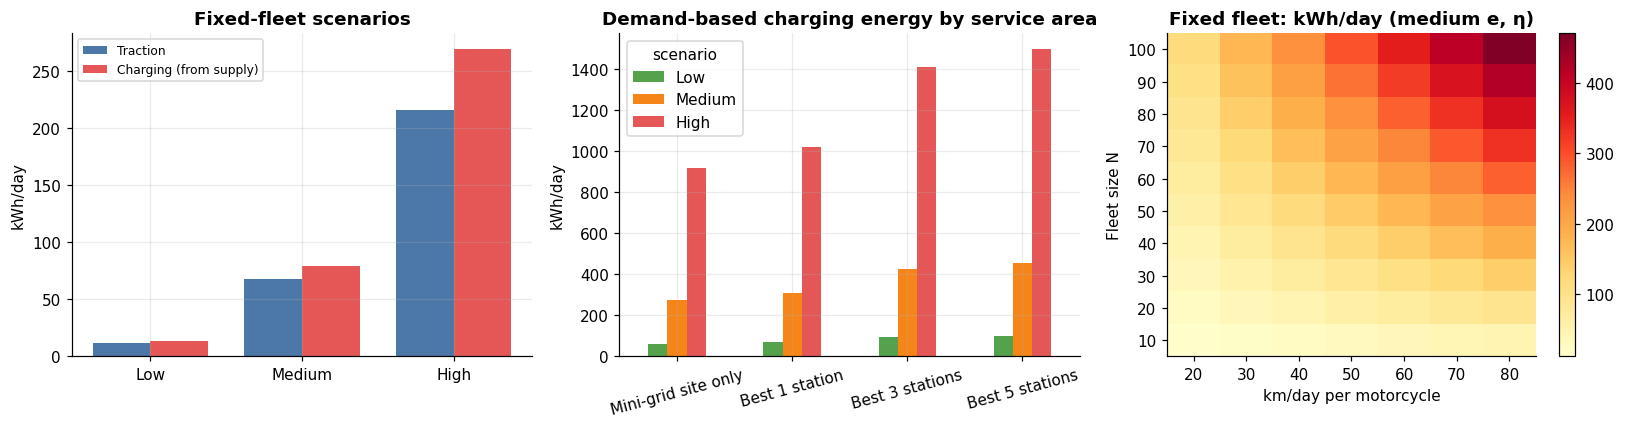

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(len(SC)); w = .38
axs[0].bar(x - w / 2, SC["E_traction_kWh_day"], w, label="Traction", color="#4c78a8")
axs[0].bar(x + w / 2, SC["E_charging_kWh_day"], w, label="Charging (from supply)", color="#e45756")
axs[0].set_xticks(x); axs[0].set_xticklabels(SC.index); axs[0].set_ylabel("kWh/day"); axs[0].legend(fontsize=8)
axs[0].set_title("Fixed-fleet scenarios", fontweight="bold")

piv = DEMSC.pivot(index="service_area", columns="scenario", values="E_charging").reindex(list(SERVICE))[["Low", "Medium", "High"]]
piv.plot.bar(ax=axs[1], color=["#54a24b", "#f58518", "#e45756"], rot=15)
axs[1].set_ylabel("kWh/day"); axs[1].set_xlabel(""); axs[1].set_title("Demand-based charging energy by service area", fontweight="bold")

Ns = np.arange(10, 101, 10); ds = np.arange(20, 81, 10)
Z = np.array([[e_charging(n, d, SC.loc["Medium", "e_kWh_100km"], SC.loc["Medium", "eta"]) for d in ds] for n in Ns])
im = axs[2].imshow(Z, origin="lower", aspect="auto", cmap="YlOrRd")
axs[2].set_xticks(range(len(ds))); axs[2].set_xticklabels(ds); axs[2].set_yticks(range(len(Ns))); axs[2].set_yticklabels(Ns)
axs[2].set_xlabel("km/day per motorcycle"); axs[2].set_ylabel("Fleet size N"); axs[2].grid(False)
axs[2].set_title("Fixed fleet: kWh/day (medium e, η)", fontweight="bold"); plt.colorbar(im, ax=axs[2])
plt.tight_layout(); plt.show()

In [ ]:
# ---- per-station sizing (medium demand-based scenario, population added by each chosen station) ----
r = DM.loc["Medium"].to_dict()
rows = []
for k, (j, p_add) in enumerate(zip(chosen, marg)):
    res = demand_energy(p_add, **r)
    rows.append({"station": f"S{k + 1}", "candidate": CAND.loc[j, "id"], "population_added": round(p_add), "N_bikes": res["N_bikes"],
                 "E_charging_kWh_day": round(res["E_charging"], 1), "peak_charging_kW": round(res["peak_kW"], 1),
                 "feeder_distance_m": CAND.loc[j, "dist_to_minigrid_m"]})
STATION_SIZING = pd.DataFrame(rows)
display(STATION_SIZING)
print("Use this to check each station against local supply: the peak kW must fit the feeder, inverter and battery limits (section 9).")

# every scenario in one place for the mini-grid section
ALL_SCEN = {}
for n, rw in SC.iterrows():
    ALL_SCEN[f"Fixed-{n}"] = (rw["E_charging_kWh_day"], rw["Peak_charging_kW"])
for n, rw in DM.iterrows():
    res = demand_energy(SERVICE[DEFAULT_AREA], **rw.to_dict())
    ALL_SCEN[f"Demand-{n}"] = (res["E_charging"], res["peak_kW"])

,station,candidate,population_added,N_bikes,E_charging_kWh_day,peak_charging_kW,feeder_distance_m
0,S1,C03,6700,84,307.9,75.6,206.0
1,S2,C35,1364,18,62.7,16.2,3090.0
2,S3,C44,1200,15,55.1,13.5,5628.0
3,S4,C42,392,5,18.0,4.5,5866.0
4,S5,C22,212,3,9.7,2.7,1082.0


Use this to check each station against local supply: the peak kW must fit the feeder, inverter and battery limits (section 9).


## 9 · Mini-grid energy feasibility (proposal §4.5)

Installed capacity is not energy available for charging. A defensible assessment needs generation, existing load, losses, storage and inverter limits, ideally hourly. The REA/KIAT energy-management centre in Abuja monitors these systems, so that is the place to request data.

- **Operator data supplied** → headroom and hourly peak check.
- **Operator data missing** → energy availability is reported as **UNASSESSED**; the charts below are *illustrative* and not feasibility claims.

Existing customers will keep growing (many homes and businesses in the community were reported as not yet connected), so headroom measured today may shrink.

Specific yield: annual mean 4.10 kWh/kWp/day [PVGIS (fixed, 14 % losses)]; worst month 3.34


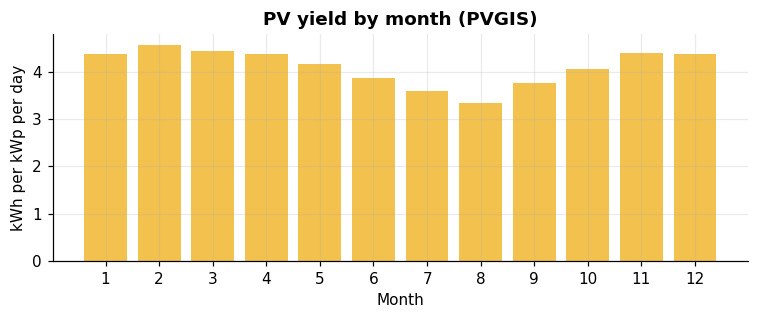

ENERGY AVAILABILITY: UNASSESSED. Load and loss data are missing, so no supportable-fleet number is claimed.


In [ ]:
MG = {"pv_kwp": 900,                 # REPORTED publicly for Rubochi; unverified (confirm the Rubochi-only value and the 3 sub-systems)
      "existing_load_kwh_day": None, "system_loss_frac": None, "battery_kwh": None, "inverter_kw": None}
CHARGE_WINDOW = (10, 16)             # hours when charging is allowed (solar hours, ASSUMPTION)

def pvgis(lat, lon):
    r = requests.get("https://re.jrc.ec.europa.eu/api/v5_2/PVcalc",
                     params={"lat": lat, "lon": lon, "peakpower": 1, "loss": 14, "outputformat": "json"}, timeout=40)
    r.raise_for_status(); js = r.json()
    annual = float(js["outputs"]["totals"]["fixed"]["E_d"])
    monthly = pd.DataFrame(js["outputs"]["monthly"]["fixed"])[["month", "E_d"]]
    return annual, monthly

YIELD, YIELD_SRC, MONTHLY = None, None, None
if FETCH_PVGIS:
    try:
        YIELD, MONTHLY = pvgis(*CENTRE); YIELD_SRC = "PVGIS (fixed, 14 % losses)"
    except Exception as ex:
        print("PVGIS lookup failed:", ex)
if YIELD is None:
    YIELD, YIELD_SRC = 4.5, "ASSUMPTION (verify)"
YIELD_WORST = float(MONTHLY["E_d"].min()) if MONTHLY is not None else YIELD * 0.8
print(f"Specific yield: annual mean {YIELD:.2f} kWh/kWp/day [{YIELD_SRC}]; worst month {YIELD_WORST:.2f}"
      + ("" if MONTHLY is not None else "  (worst month ASSUMED at 80 % of mean)"))

if MONTHLY is not None:
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(MONTHLY["month"], MONTHLY["E_d"], color="#f2c14e"); ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month"); ax.set_ylabel("kWh per kWp per day"); ax.set_title("PV yield by month (PVGIS)", fontweight="bold")
    plt.tight_layout(); plt.show()

gen_avg   = MG["pv_kwp"] * YIELD if MG["pv_kwp"] else None
gen_worst = MG["pv_kwp"] * YIELD_WORST if MG["pv_kwp"] else None
if gen_avg and MG["existing_load_kwh_day"] is not None and MG["system_loss_frac"] is not None:
    HEADROOM = max(0.0, gen_worst * (1 - MG["system_loss_frac"]) - MG["existing_load_kwh_day"])
    print(f"Estimated daily headroom (worst month): {HEADROOM:,.0f} kWh/day (daily balance only; see the hourly check)")
else:
    HEADROOM = None
    print("ENERGY AVAILABILITY: UNASSESSED. Load and loss data are missing, so no supportable-fleet number is claimed.")

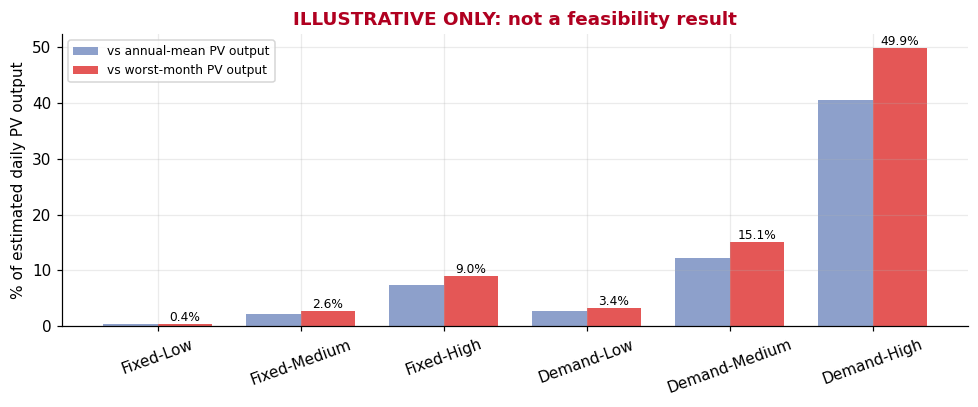

Estimated daily PV output: 3,690 kWh (mean) / 3,006 kWh (worst month); before losses, existing customers and storage limits.
A scenario is only plausible if the share you can actually spare exceeds the share shown. That spare share is the unknown.


In [ ]:
if gen_avg:
    names = list(ALL_SCEN)
    need_avg   = np.array([ALL_SCEN[n][0] for n in names]) / gen_avg * 100
    need_worst = np.array([ALL_SCEN[n][0] for n in names]) / gen_worst * 100
    fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(names)); w = .38
    ax.bar(x - w / 2, need_avg, w, label="vs annual-mean PV output", color="#8da0cb")
    ax.bar(x + w / 2, need_worst, w, label="vs worst-month PV output", color="#e45756")
    for i, v in enumerate(need_worst):
        ax.text(i + w / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20); ax.set_ylabel("% of estimated daily PV output")
    ax.set_title("ILLUSTRATIVE ONLY: not a feasibility result", fontweight="bold", color="#b00020"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    print(f"Estimated daily PV output: {gen_avg:,.0f} kWh (mean) / {gen_worst:,.0f} kWh (worst month); before losses, existing customers and storage limits.")
    print("A scenario is only plausible if the share you can actually spare exceeds the share shown. That spare share is the unknown.")

In [ ]:
if OPERATOR_LOAD.exists():
    hp = pd.read_csv(OPERATOR_LOAD).sort_values("hour")
    in_win = hp["hour"].between(CHARGE_WINDOW[0], CHARGE_WINDOW[1] - 1).values
    n_h = max(CHARGE_WINDOW[1] - CHARGE_WINDOW[0], 1)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(hp["hour"], hp["load_kw"], color="k", lw=2, label="Existing load")
    for name, c in zip(["Fixed-Medium", "Demand-Medium", "Demand-High"], ["#54a24b", "#f58518", "#e45756"]):
        e_kwh, peak = ALL_SCEN[name]
        add_kw = np.where(in_win, min(e_kwh / n_h, peak), 0)
        ax.plot(hp["hour"], hp["load_kw"].values + add_kw, color=c, ls="--", label=f"+ {name}")
    if MG["inverter_kw"]:
        ax.axhline(MG["inverter_kw"], color="#b00020", lw=1.5, label="Inverter rating")
    ax.axvspan(*CHARGE_WINDOW, color="gold", alpha=.15, label="Charging window")
    ax.set_xlabel("Hour of day"); ax.set_ylabel("kW"); ax.set_title("Hourly load with added charging demand", fontweight="bold"); ax.legend(fontsize=8)
    plt.show()
else:
    print("No hourly load file found -> hourly and peak-power feasibility NOT assessed.")

No hourly load file found -> hourly and peak-power feasibility NOT assessed.


## 10 · Operating-cost comparison (optional)
A cost-per-kilometre comparison with petrol motorcycles is often what decides adoption. Fill in the three inputs from the NBS petrol price, a typical petrol-motorcycle consumption figure, and the mini-grid tariff. The cell stays silent until all three are supplied.

In [ ]:
ECON = {"petrol_ngn_per_litre": None, "petrol_l_per_100km": None, "tariff_ngn_per_kwh": None}
if all(v is not None for v in ECON.values()):
    petrol_km = ECON["petrol_ngn_per_litre"] * ECON["petrol_l_per_100km"] / 100
    rows = []
    for n, r in DM.iterrows():
        ev_km = ECON["tariff_ngn_per_kwh"] * r["e_kWh_100km"] / 100 / r["eta"]
        rows.append({"scenario": n, "petrol_NGN_per_km": round(petrol_km, 1), "electric_NGN_per_km": round(ev_km, 1),
                     "saving_per_km_%": round((1 - ev_km / petrol_km) * 100)})
    display(pd.DataFrame(rows))
else:
    print("Economics not computed: set the three values in ECON (petrol price, petrol l/100 km, tariff).")

Economics not computed: set the three values in ECON (petrol price, petrol l/100 km, tariff).


## 11 · Sensitivity analysis (proposal §4.6)
1. **Energy:** one-at-a-time tornado and a Monte Carlo run, for both the fixed-fleet and the demand-based model.
2. **Suitability weights:** do the same candidates stay on top when `R, D, C` weights change?
3. **Catchment distance:** does the ranking depend on how far a destination "reaches"?

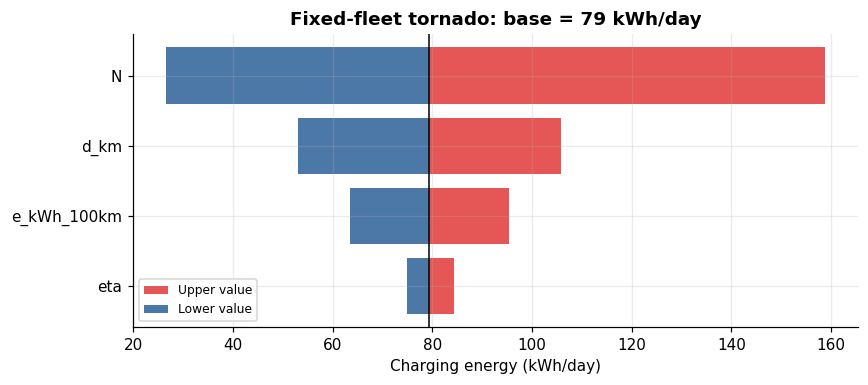

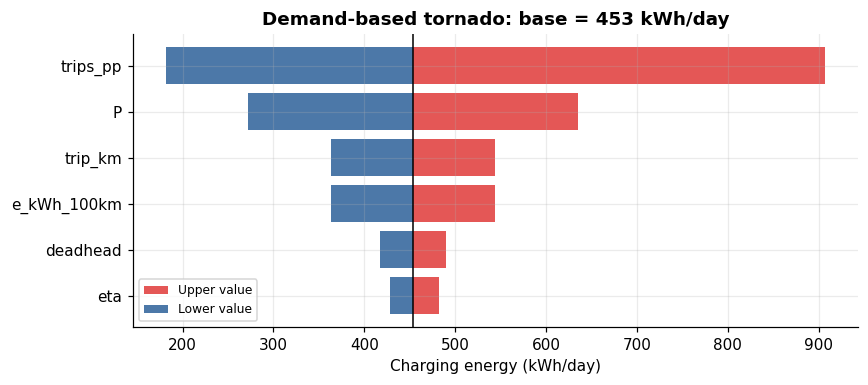

Dominant input: fixed-fleet -> N; demand-based -> trips_pp


In [ ]:
def tornado(base, ranges, func, title):
    E0 = func(**base)
    rows = []
    for p, (lo, hi) in ranges.items():
        vals = [func(**{**base, p: v}) for v in (lo, hi)]
        rows.append((p, min(vals), max(vals)))
    t = pd.DataFrame(rows, columns=["input", "low", "high"]).assign(span=lambda d: d["high"] - d["low"]).sort_values("span")
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.barh(t["input"], t["high"] - E0, left=E0, color="#e45756", label="Upper value")
    ax.barh(t["input"], t["low"] - E0, left=E0, color="#4c78a8", label="Lower value")
    ax.axvline(E0, color="k", lw=1); ax.set_xlabel("Charging energy (kWh/day)")
    ax.set_title(f"{title}: base = {E0:.0f} kWh/day", fontweight="bold"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
    return t.iloc[-1]["input"]

# fixed fleet
fx = lambda N, d_km, e_kWh_100km, eta: e_charging(N, d_km, e_kWh_100km, eta)
b1 = SC.loc["Medium", ["N", "d_km", "e_kWh_100km", "eta"]].to_dict()
r1 = {p: (SC[p].min(), SC[p].max()) for p in b1}
top1 = tornado(b1, r1, fx, "Fixed-fleet tornado")

# demand based (population varies +/-40 % to reflect service-area and population uncertainty)
P0 = SERVICE[DEFAULT_AREA]
fd = lambda P, trips_pp, trip_km, deadhead, e_kWh_100km, eta: P * trips_pp * trip_km * deadhead * e_kWh_100km / 100 / eta
b2 = {"P": P0, **DM.loc["Medium", ["trips_pp", "trip_km", "deadhead", "e_kWh_100km", "eta"]].to_dict()}
r2 = {"P": (0.6 * P0, 1.4 * P0), **{p: (DM[p].min(), DM[p].max()) for p in ["trips_pp", "trip_km", "deadhead", "e_kWh_100km", "eta"]}}
top2 = tornado(b2, r2, fd, "Demand-based tornado")
print(f"Dominant input: fixed-fleet -> {top1}; demand-based -> {top2}")

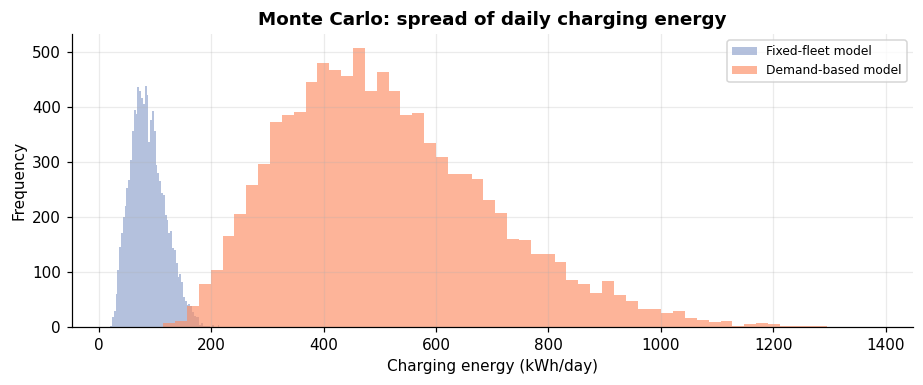

Fixed-fleet: P5 42, median 85, P95 144 kWh/day
Demand-based: P5 253, median 490, P95 863 kWh/day
Report ranges, not single numbers. The two models differ because the fixed fleet was assumed, while the demand-based one is tied to population and trip rate.


In [ ]:
rng = np.random.default_rng(42)
tri = lambda lo, mode, hi: rng.triangular(lo, mode, hi, 10000)
mc1 = e_charging(tri(SC.N.min(), SC.loc["Medium", "N"], SC.N.max()), tri(SC.d_km.min(), SC.loc["Medium", "d_km"], SC.d_km.max()),
                 tri(4.0, 5.0, 6.0), tri(.80, .85, .90))
mc2 = fd(tri(.6 * P0, P0, 1.4 * P0), tri(DM.trips_pp.min(), DM.loc["Medium", "trips_pp"], DM.trips_pp.max()),
         tri(DM.trip_km.min(), DM.loc["Medium", "trip_km"], DM.trip_km.max()), tri(DM.deadhead.min(), DM.loc["Medium", "deadhead"], DM.deadhead.max()),
         tri(4.0, 5.0, 6.0), tri(.80, .85, .90))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hist(mc1, bins=60, alpha=.65, color="#8da0cb", label="Fixed-fleet model")
ax.hist(mc2, bins=60, alpha=.65, color="#fc8d62", label="Demand-based model")
ax.set_xlabel("Charging energy (kWh/day)"); ax.set_ylabel("Frequency"); ax.legend(fontsize=8)
ax.set_title("Monte Carlo: spread of daily charging energy", fontweight="bold"); plt.tight_layout(); plt.show()
for lab, mc in (("Fixed-fleet", mc1), ("Demand-based", mc2)):
    p5, p50, p95 = np.percentile(mc, [5, 50, 95])
    print(f"{lab}: P5 {p5:.0f}, median {p50:.0f}, P95 {p95:.0f} kWh/day")
print("Report ranges, not single numbers. The two models differ because the fixed fleet was assumed, while the demand-based one is tied to population and trip rate.")

,id,share_of_draws_in_top3,baseline_rank
0,C01,0.805,1
1,C02,0.662,2
2,C03,0.621,3
3,C04,0.309,4
4,C06,0.262,6
5,C28,0.128,28
6,C09,0.078,9
7,C26,0.071,26


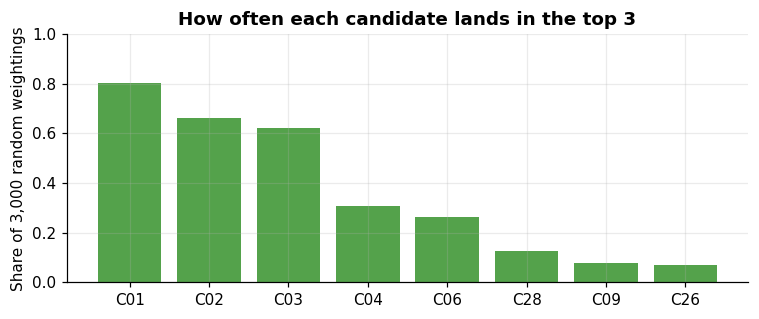

,catchment_m,rank_correlation,top5_overlap_with_baseline,top5
0,500,0.950,4,"C01, C02, C03, C05, C08"
1,1000,0.987,5,"C01, C02, C03, C04, C05"
2,1500,1.000,5,"C01, C02, C03, C04, C05"
3,2000,0.998,5,"C01, C02, C03, C04, C05"
4,3000,0.994,5,"C01, C02, C03, C04, C05"


In [ ]:
# ---- suitability-weight stability ----
M = CAND[["R", "D", "C"]].values
Wd = rng.dirichlet([1, 1, 1], 3000)
SIs = Wd @ M.T
top3 = np.argsort(-SIs, axis=1)[:, :3]
freq = (pd.Series(top3.ravel()).value_counts() / len(Wd)).head(8)
stab = pd.DataFrame({"id": CAND["id"].values[freq.index], "share_of_draws_in_top3": freq.values.round(3), "baseline_rank": [int(i) + 1 for i in freq.index]})
display(stab)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(stab["id"], stab["share_of_draws_in_top3"], color="#54a24b"); ax.set_ylim(0, 1)
ax.set_ylabel("Share of 3,000 random weightings"); ax.set_title("How often each candidate lands in the top 3", fontweight="bold")
plt.tight_layout(); plt.show()

# ---- catchment-distance sensitivity ----
rows = []
for c in (500, 1000, 1500, 2000, 3000):
    Dc = minmax(compute_D(c))
    SIc = WEIGHTS["R"] * CAND["R"] + WEIGHTS["D"] * Dc + WEIGHTS["C"] * CAND["C"]
    t5 = set(CAND["id"][np.argsort(-SIc.values)[:5]])
    rows.append({"catchment_m": c, "rank_correlation": round(pd.Series(SIc.values).rank().corr(CAND["SI"].rank()), 3),
                 "top5_overlap_with_baseline": len(t5 & set(CAND["id"].head(5))), "top5": ", ".join(sorted(t5))})
display(pd.DataFrame(rows))

## 12 · Data-gap assessment, exports and provenance (proposal §5)

In [ ]:
n_extra = sum(cnt(k) for k in L if k.startswith("x_"))
gaps = pd.DataFrame([
    ["Mini-grid coordinates and PV field locations", "verified" if MINIGRID_VERIFIED else "NOT verified", "High", "All spatial results are anchored here", "Get coordinates and layout from REA / operator; check on imagery"],
    ["Operator load profile (hourly)", "available" if OPERATOR_LOAD.exists() else "MISSING", "Critical", "Needed to claim any supportable fleet size", "Request 12 months of hourly load and generation from REA"],
    ["Battery, inverter, controller specs", "available" if all(MG[k] for k in ("battery_kwh", "inverter_kw")) else "MISSING", "Critical", "Sets peak charging power and storage limit", "Request datasheets and as-built drawings"],
    ["Existing load, losses, customer growth", "available" if MG["existing_load_kwh_day"] is not None and MG["system_loss_frac"] is not None else "MISSING", "Critical", "Needed for headroom", "Request metering/billing summaries and connection pipeline"],
    ["Field road-condition survey", "available" if SV is not None else "MISSING", "High", "Road score is only a proxy without it", "Survey the top zones and the covered area"],
    ["Population", POP_SOURCE, "High" if "ASSUMPTION" in POP_SOURCE else "Medium", "Drives coverage and demand-based fleet size", "Download WorldPop and set POP_TIF" if "ASSUMPTION" in POP_SOURCE else "Cross-check with a household count"],
    ["Building footprints", f"{BUILD_SRC or 'none'} ({max(cnt('osm_buildings'), cnt('overture_bld')):,})", "Medium", "Demand proxy", "Compare OSM, Overture and imagery"],
    ["Destination coverage (markets, schools, hubs)", f"{cnt('osm_amenity') + cnt('overture_poi') + n_extra} POIs", "High", "Destination weights drive D", "Add GRID3 schools/markets via EXTRA_GRID3; GPS-map key destinations"],
    ["Network connectivity", f"{len(comps)} components; largest = {main_len / tot_len:.0%} of length ({len(bridges)} bridged)", "Medium", "Disconnected pieces cannot be routed", "Verify bridged links; fix gaps on imagery / in OSM"],
    ["Transport demand (trips, fares, riders)", "ASSUMED (section 8)", "High", "Sets fleet size and energy", "Rider and household survey"],
    ["Terrain / slope", "sampled" if GRADE is not None else "NOT fetched", "Low", "Affects energy per km and road passability", "Set FETCH_ELEVATION = True"],
    ["Vehicle specs (consumption, charger, battery)", "ASSUMED", "Medium", "Drives every energy figure", "Use datasheet values for the intended model"],
    ["Operating cost inputs (petrol, tariff)", "supplied" if all(v is not None for v in ECON.values()) else "MISSING", "Medium", "Needed for the cost comparison", "NBS petrol price, mini-grid tariff"],
], columns=["item", "status", "priority", "why it matters", "next action"])
gaps

,item,status,priority,why it matters,next action
0,Mini-grid coordinates and PV field locations,NOT verified,High,All spatial results are anchored here,Get coordinates and layout from REA / operator; check on...
1,Operator load profile (hourly),MISSING,Critical,Needed to claim any supportable fleet size,Request 12 months of hourly load and generation from REA
2,"Battery, inverter, controller specs",MISSING,Critical,Sets peak charging power and storage limit,Request datasheets and as-built drawings
3,"Existing load, losses, customer growth",MISSING,Critical,Needed for headroom,Request metering/billing summaries and connection pipeline
4,Field road-condition survey,MISSING,High,Road score is only a proxy without it,Survey the top zones and the covered area
5,Population,Overture buildings x 4 persons/building (ASSUMPTION),High,Drives coverage and demand-based fleet size,Download WorldPop and set POP_TIF
6,Building footprints,"Overture (2,677)",Medium,Demand proxy,"Compare OSM, Overture and imagery"
7,"Destination coverage (markets, schools, hubs)",2 POIs,High,Destination weights drive D,Add GRID3 schools/markets via EXTRA_GRID3; GPS-map key d...
8,Network connectivity,8 components; largest = 94% of length (3 bridged),Medium,Disconnected pieces cannot be routed,Verify bridged links; fix gaps on imagery / in OSM
9,"Transport demand (trips, fares, riders)",ASSUMED (section 8),High,Sets fleet size and energy,Rider and household survey


In [ ]:
CAND.drop(columns=["node"]).to_crs(CRS_GEO).to_file(OUT / "candidate_charging_locations.geojson", driver="GeoJSON")
CAND.drop(columns=["node", "geometry"]).to_csv(OUT / "candidate_charging_locations.csv", index=False)
DEST.drop(columns=["node"]).to_crs(CRS_GEO).to_file(OUT / "destinations.geojson", driver="GeoJSON")
ZONES.to_csv(OUT / "candidate_zones.csv")
ST.to_csv(OUT / "coverage_stations.csv", index=False)
STATION_SIZING.to_csv(OUT / "station_sizing_medium_demand.csv", index=False)
DEMSC.to_csv(OUT / "demand_based_scenarios.csv", index=False)
SC.round(2).to_csv(OUT / "fixed_fleet_scenarios.csv")
dq.to_csv(OUT / "data_quality_register.csv", index=False)
gaps.to_csv(OUT / "data_gap_assessment.csv", index=False)
stab.to_csv(OUT / "weight_sensitivity_top3.csv", index=False)

meta = {"run_utc": dt.datetime.utcnow().isoformat(timespec="seconds"), "centre": CENTRE, "minigrid_verified": MINIGRID_VERIFIED,
        "radius_m": RADIUS_M, "weights": WEIGHTS, "catchment_m": CATCHMENT_M, "cover_catch_m": COVER_CATCH_M,
        "population_source": POP_SOURCE, "building_source": BUILD_SRC, "pv_kwp_reported": MG["pv_kwp"],
        "yield_kwh_per_kwp_day": {"mean": YIELD, "worst_month": YIELD_WORST, "source": YIELD_SRC},
        "layer_counts": {k: len(v) for k, v in L.items()},
        "network": {"components": len(comps), "bridged": len(bridges), "main_km": round(main_len / 1000, 2)},
        "versions": {"python": sys.version.split()[0], "geopandas": gpd.__version__, "pandas": pd.__version__, "networkx": nx.__version__, "numpy": np.__version__}}
(OUT / "run_metadata.json").write_text(json.dumps(meta, indent=2, default=str))
print("Saved to", OUT.resolve())
for p in sorted(OUT.iterdir()):
    print(" -", p.name)

Saved to /content/rubochi_outputs
 - candidate_charging_locations.csv
 - candidate_charging_locations.geojson
 - candidate_zones.csv
 - coverage_stations.csv
 - data_gap_assessment.csv
 - data_quality_register.csv
 - demand_based_scenarios.csv
 - destinations.geojson
 - fixed_fleet_scenarios.csv
 - run_metadata.json
 - station_sizing_medium_demand.csv
 - weight_sensitivity_top3.csv


In [ ]:
print("=" * 72)
print("RUBOCHI SCREENING v2: HEADLINE RESULTS (preliminary)")
print("=" * 72)
print(f"Network: {len(comps)} component(s) after {len(bridges)} bridge(s); routable length {main_len / 1000:.1f} km")
print(f"Population source: {POP_SOURCE}")
print("Candidate zones (geographic suitability only):")
for z, r in ZONES.head(3).iterrows():
    print(f"  {z}: best {r['best_id']} SI={r['best_SI']:.2f} ({r['lat']:.5f}, {r['lon']:.5f}), {r['candidates']} candidates, ~{r['mean_dist_to_minigrid_m']:.0f} m from mini-grid")
print(f"Coverage: mini-grid site alone {mg_pop / POP_ALL:.0%}; {len(chosen)} greedy stations {cum[-1] / POP_ALL:.0%} of the box population")
print("Daily charging energy, fixed fleet (ASSUMED): " + ", ".join(f"{k} {v:.0f}" for k, v in SC["E_charging_kWh_day"].items()) + " kWh")
dd = DEMSC[DEMSC["service_area"] == DEFAULT_AREA].set_index("scenario")["E_charging"]
print(f"Daily charging energy, demand-based ({DEFAULT_AREA}, ASSUMED trip rates): " + ", ".join(f"{k} {v:.0f}" for k, v in dd.items()) + " kWh")
print("Energy availability:", f"headroom {HEADROOM:,.0f} kWh/day" if HEADROOM is not None else "UNASSESSED (operator data missing)")
print("Road condition basis:", "field survey" if SV is not None else "attribute proxy only")

RUBOCHI SCREENING v2: HEADLINE RESULTS (preliminary)
Network: 8 component(s) after 3 bridge(s); routable length 60.6 km
Population source: Overture buildings x 4 persons/building (ASSUMPTION)
Candidate zones (geographic suitability only):
  Z1: best C01 SI=0.82 (8.53762, 7.03236), 15 candidates, ~697 m from mini-grid
Coverage: mini-grid site alone 56%; 5 greedy stations 92% of the box population
Daily charging energy, fixed fleet (ASSUMED): Low 13, Medium 79, High 270 kWh
Daily charging energy, demand-based (Best 5 stations, ASSUMED trip rates): Low 101, Medium 454, High 1499 kWh
Energy availability: UNASSESSED (operator data missing)
Road condition basis: attribute proxy only


## Interpreting and reporting the results

**What you can claim now**
- A mapped, routable network, its gaps, and how OSM and GRID3 compare.
- A *provisional* set of candidate **zones** (not single points) and how stable they are to weights and catchment.
- How much population a few stations could cover along the road network, and the feeder-distance trade-off.
- Daily charging energy under *assumed* scenarios, with ranges from the sensitivity analysis.

**What you cannot claim yet**
- That the mini-grid can support any particular number of motorcycles (needs hourly load, battery and inverter data).
- That a station has demand, land access or a viable business case (needs the rider survey and cost inputs).
- That roads are passable year-round (needs the field survey, including rainy-season observations).

**Highest-value next steps**
1. Get the operator data from REA and verify mini-grid / PV-field coordinates.
2. Download WorldPop (set `POP_TIF`) and the GRID3 school and market layers (`EXTRA_GRID3`).
3. Run a short rider and household survey for trip rate, trip length and trips per motorcycle; replace the demand-scenario assumptions.
4. Survey the top zones and the covered area for road condition; re-run sections 4–8.

*AI-use disclosure: generative AI assisted with drafting this notebook. The author remains responsible for verifying data, assumptions, calculations and conclusions.*